# 01. vLLM 서빙 기초: 요청 한 건의 여정

GLM-5.3-Flash에 보낸 요청 한 건은 서버 안에서 프로세스 세 종류를 지나고, 객체 여덟 개로 모양을 바꾼 뒤 답이 되어 돌아옵니다. 이 노트북은 그 여정 전체를 코드 위에서 한 번 걷습니다. 다음 노트북들은 이 지도의 한 구간씩 확대하므로, 여기서는 세부보다 **어디서 무엇이 결정되는가**를 자기 말로 설명할 수 있게 되는 것이 목표입니다.

기준 소스는 vLLM v0.32.0(커밋 `5df63a7`)입니다. 코드는 읽었고, 스케줄러 한 곳만 실제 클래스를 CPU에서 불러 수업용 모델과 맞춰 보았습니다(절 1, 실제 클래스 실행). 이 소스로 서버를 띄운 적은 없습니다. 그래서 이 노트북의 문장은 "서버가 이렇게 동작했다"가 아니라 "코드에 이렇게 적혀 있다" 또는 "클래스를 불렀더니 이렇게 나왔다"로 읽어야 합니다.

## 학습 목표

- 요청 한 건의 여정을 객체 이름과 프로세스 이름으로 말합니다.
- 왜 실행 단위가 요청이 아니라 step인지, 왜 프로세스를 나눴는지 설명합니다.
- 서버 초기화 순서를 말하고, 그 순서의 이유와 KV 크기를 정하는 방법을 설명합니다.
- 코드의 request 상태 12개를 PDF의 상태 4개와 구분합니다.
- Model Runner V2와 async scheduling이 켜지는 조건을 정확하게 말합니다.

## 수업 시간표

| 절 | 내용 | 분 |
|---|---|---:|
| 0 | 요청 한 건의 지도 | 4 |
| 1 | step: 실행의 단위 | 8 |
| 2 | 프로세스 경계 | 8 |
| 3 | 서버 초기화 순서 | 11 |
| 4 | request 경로와 객체 사슬 | 11 |
| 5 | request 상태 12개 | 4 |
| 6 | Model Runner V2와 async scheduling | 5 |
| 7 | Python frontend와 수업 서버 | 3 |
| 8 | 직접 해보기, 확인 질문, 정리 | 6 |

## 호출 규모

모델 호출 0회, 유료 API 호출 0회, 키와 GPU가 필요 없습니다. 네트워크에도 접속하지 않습니다. 실패 재현 셀 하나가 루프백 소켓을 `bind`만 하고 바로 닫습니다.

In [1]:
import enum
import errno
import socket
import sys

import vllm_lab
from vllm_lab import sched_sim, view

print("기준 vLLM:", vllm_lab.VLLM_VERSION)
print("기준 커밋:", vllm_lab.VLLM_COMMIT)
print("이 kernel에 vllm이 올라와 있는가:", "vllm" in sys.modules)
print("이 kernel에 torch가 올라와 있는가:", "torch" in sys.modules)

# 그림의 범례가 막대를 가리지 않도록 맨 위에 빈 줄을 하나 둔다.
LEGEND_ROW = {"lane": " ", "start": 0, "end": 0, "label": "", "kind": "other"}

기준 vLLM: 0.32.0
기준 커밋: 5df63a7203cdb9328d824a27b682e77c7b9928be
이 kernel에 vllm이 올라와 있는가: False
이 kernel에 torch가 올라와 있는가: False


### 수업 서버와의 차이

이 노트북의 경로 설명은 모두 v0.32.0의 **Python frontend** 기준입니다. 수업 Pod 이미지는 `Day07/README.md:75`에 v0.28.1rc1 dev 빌드로 적혀 있고(R-01), 레시피 기본 명령은 Rust frontend를 켭니다(P1-49). 수업 Pod가 어느 frontend로 떠 있는지는 확인되지 않았습니다. 그러므로 아래 내용을 "수업 서버가 이렇게 동작한다"로 옮겨 말하면 안 됩니다. 차이의 내용은 절 7에서 다룹니다.

코드 인용은 전부 v0.32.0 커밋에 고정한 링크입니다. 링크가 가리키는 줄을 직접 열어 보면서 읽기를 권합니다.

## 0. 요청 한 건의 지도 (4분)

앞으로 모든 Part가 이 표의 한 구간을 확대합니다. 처음 볼 때는 **객체** 칸과 **어디서** 칸만 눈에 익히면 충분합니다.

| 정거장 | 어디서 | 무엇이 일어나나 | 객체 |
|---|---|---|---|
| 1 HTTP 수신 | API server | route가 요청을 받아 handler로 넘긴다 | `ChatCompletionRequest` |
| 2 렌더링·tokenize | API server | chat template 렌더링, token 변환, 생성 한도 계산 | `EngineInput` |
| 3 ADD 전송 | API server → EngineCore | 결과 queue를 먼저 등록하고 ZMQ로 보낸다 | `EngineCoreRequest` |
| 4 대기 | EngineCore | `Request`로 바뀌어 waiting에 들어간다 | `Request` |
| 5 schedule | EngineCore | 예산과 KV block을 배정하고 prefix cache를 조회한다 | `SchedulerOutput` |
| 6 forward·sampling | GPU worker | KV를 쓰고 읽으며 계산한다. draft token도 여기서 검증된다 | `ModelRunnerOutput` |
| 7 결과 반영 | EngineCore | 출력 token 반영, 틀린 draft 되감기, 종료 판정 | `EngineCoreOutputs` |
| 8 detokenize·파싱 | API server | 증분 detokenize, stop string 검사, reasoning·도구 파서, SSE | `RequestOutput` |
| 9 반납 | EngineCore | block 참조를 풀고 free queue로 되돌린다. KV 값은 남는다 | - |

**공식 문서.** 이 여정 표 자체는 공식 문서에 없습니다. 프로세스 세 종류는 [docs/design/arch_overview.md:67](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/arch_overview.md#L67) 절이 설명합니다. 코드 위치는 절 1부터 하나씩 겁니다.

대화의 다음 턴은 이어 붙이기가 아닙니다. client가 대화 전체를 담은 **새 요청**을 보내 정거장 1부터 다시 시작합니다. 이 사실의 값어치는 05에서 드러납니다.

아래 그림은 같은 표를 프로세스별로 다시 그린 것입니다. 그림 글자는 영어로 적었고, 같은 줄 안은 번호 순서대로 읽습니다. 화살표는 프로세스를 건너는 곳에만 그렸습니다.

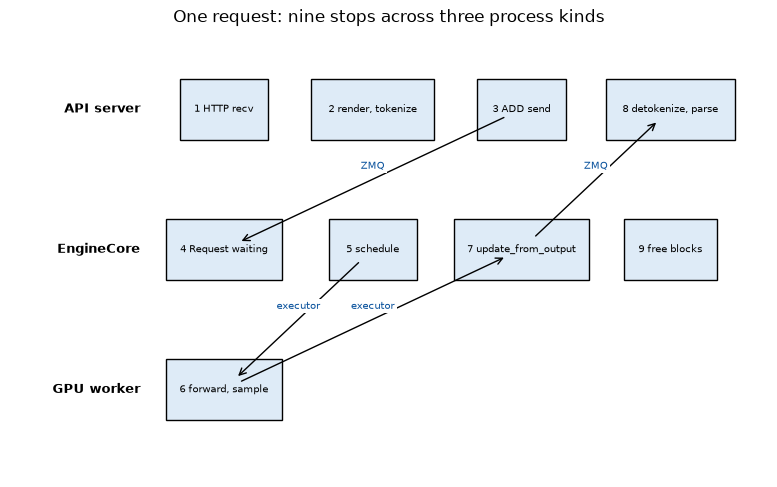

In [2]:
lanes = {
    "API server": ["1 HTTP recv", "2 render, tokenize", "3 ADD send", "8 detokenize, parse"],
    "EngineCore": ["4 Request waiting", "5 schedule", "7 update_from_output", "9 free blocks"],
    "GPU worker": ["6 forward, sample"],
}
# 같은 줄 안에서는 번호 순서대로 읽는다. 화살표는 프로세스를 건너는 곳만 그린다.
arrows = [
    ("3 ADD send", "4 Request waiting", "ZMQ"),
    ("5 schedule", "6 forward, sample", "executor"),
    ("6 forward, sample", "7 update_from_output", "executor"),
    ("7 update_from_output", "8 detokenize, parse", "ZMQ"),
]
view.lane_diagram(lanes, arrows, title="One request: nine stops across three process kinds")

7번에서 5번으로 돌아가는 화살표는 그리지 않았지만 실제로는 고리입니다. 요청이 끝날 때까지 5, 6, 7이 되풀이되고, 그 한 바퀴가 다음 절의 주제인 step입니다.

**왜 이렇게 설계했나.** 이 표는 수업이 코드를 읽어 만든 정리이고, 정거장 번호는 vLLM에 없는 말입니다. 프로세스와 객체의 이름만 코드에 있습니다(P1-03, P1-27). 왜 프로세스를 나눴는지는 절 2에서 PR과 이슈로 확인합니다.

## 1. step: 실행의 단위 (8분)

**개념.** EngineCore는 요청을 하나씩 끝까지 처리하지 않습니다. 실행의 단위는 **step**이고, step 하나는 보통 GPU forward 한 번입니다. `step` 함수 하나가 같은 네 동작을 차례로 실행합니다(P1-01). 다만 이것은 batch queue가 없는 경로의 이야기입니다. async scheduling이 켜져 있으면 `step_fn`이 `step_with_batch_queue`가 되고, 그 호출 한 번은 새 batch를 queue에 넣기만 하거나 끝난 batch를 꺼내 `update_from_output`만 할 수도 있습니다(절 6). 한 step에 배정된 token이 0이면 forward도 돌지 않습니다.

| 순서 | 동작 | 하는 일 | 코드 |
|---:|---|---|---|
| 1 | `schedule` | 이번 step에 계산할 token을 요청별로 고른다 | [vllm/v1/engine/core.py:667](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core.py#L667) |
| 2 | `execute_model` | 고른 token으로 forward를 돌린다 | [vllm/v1/engine/core.py:668](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core.py#L668) |
| 3 | `sample_tokens` | forward 결과에서 다음 token을 뽑는다. `execute_model`이 `None`을 돌려줄 때만 부른다 | [vllm/v1/engine/core.py:676](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core.py#L676) |
| 4 | `update_from_output` | 결과를 요청에 반영하고 끝난 요청을 가린다 | [vllm/v1/engine/core.py:681](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core.py#L681) |

이 네 줄이 들어 있는 함수는 `step`([vllm/v1/engine/core.py:657](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core.py#L657))입니다. 이어지는 질문은 "요청마다 무엇을 얼마나 계산할지를 어떻게 정하는가"입니다. 답은 [vllm/v1/core/sched/scheduler.py:593](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L593)부터 몇 줄에 걸친 주석에 적혀 있습니다.

scheduler에는 prefill 단계도 decode 단계도 없습니다(P1-02, P2-03). 요청마다 두 숫자만 있습니다. 계산을 끝낸 token 수(`num_computed_tokens`)와 전체 token 수(draft까지 센 `num_tokens_with_spec`)입니다. scheduler는 매 step 앞의 숫자가 뒤의 숫자를 따라잡도록 예산 안에서 token을 나눠 줍니다. 예외가 하나 있습니다. DP prefill balancing이 일부 step을 늦출 때(`defer_prefills`)는 진행 중인 prefill 조각을 미루고 decode만 돌립니다([vllm/v1/core/sched/scheduler.py:634-638](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L634-L638), [vllm/v1/core/sched/scheduler.py:686-690](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L686-L690))(P1-02).

그 결과는 이렇습니다. 프롬프트 54 token을 가진 `doc`은 차이가 54이니 몇 step에 걸쳐 나눠 받고, 답을 쓰는 중인 요청은 방금 나온 token 하나만큼 차이가 나니 1을 받습니다. 둘 다 "차이를 메운다"는 같은 규칙이므로 **프롬프트 조각과 답 token이 한 step에 섞입니다.** 우리가 prefill, decode라고 부르는 것은 그 차이의 크기에 붙인 이름일 뿐입니다.

**공식 문서.** [docs/design/model_runner_v2.md:19](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/model_runner_v2.md#L19)은 연속한 step의 batch가 대부분 같다는 점을 적습니다. 위 네 동작과 단계 구분이 없다는 설계에 대해서는, 공식 문서에는 이 설명이 없습니다. 근거는 코드 주석입니다.

**코드.** `step`의 뼈대는 다음과 같습니다. 줄을 줄이려고 기록용 호출과 `with` 문을 뺐습니다.

```python
scheduler_output = self.scheduler.schedule(...)
future = self.model_executor.execute_model(scheduler_output, non_block=True)
grammar_output = self.scheduler.get_grammar_bitmask(scheduler_output)
model_output = future.result()
if model_output is None:
    model_output = self.model_executor.sample_tokens(grammar_output)
self._process_aborts_queue()
engine_core_outputs = self.scheduler.update_from_output(scheduler_output, model_output)
```

`model_output is None`을 검사하는 줄([vllm/v1/engine/core.py:675](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core.py#L675))은 절 6에서 다시 봅니다. `update_from_output` 바로 앞의 `_process_aborts_queue`([vllm/v1/engine/core.py:680](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core.py#L680))는 forward가 도는 동안 들어온 취소를 먼저 처리합니다.

**직접 관찰.** 이제 요청 세 개로 step을 돌려 봅니다.

**이것은 vLLM이 아니라 수업용 모델입니다.** `sched_sim`은 `schedule()`의 규칙을 FCFS, 프로세스 하나로 옮겨 적은 교육용 코드입니다. 아래 셀이 모델링하지 않은 것을 출력합니다. 이 스케줄러는 실제 `Scheduler` 클래스를 CPU에서 같은 입력으로 돌려 둔 기록(`data/reference_sched.json`, 실제 클래스 실행)과 대조했습니다. 전체 입력 검사(`scheduler_reserve_full_isl`)와 prefix cache를 모두 끈 조건에서는 38개 시나리오의 step 행이 이 모델과 전부 같았습니다. 둘 중 하나라도 켜면 달라지는 시나리오가 있습니다. 전체 입력 검사는 `SchedConfig(reserve_full_isl=True)`로 맞출 수 있고, prefix cache 쪽은 이 모델이 다루지 않습니다. 아래 `doc, faq, chat` 표는 네 조건 모두에서 실제 쪽과 같았습니다. 다만 이 기록은 서버 관찰이 아니라 클래스 호출이고, 출력 token은 손으로 만든 값이며, 실제 쪽에는 시간 칸이 없습니다. 그래서 이 표는 "vLLM이 이렇게 동작했다"가 아니라 "주석의 규칙을 따르면 이렇게 되고, 클래스를 불러도 같았다"입니다. 시각은 선언한 toy 상수의 결과이고 측정이 아닙니다.

요청은 수업의 고정 예제입니다. 프롬프트 token 수는 `doc` 54, `faq` 20, `chat` 34이고 출력은 각각 8, 6, 4 token입니다. `doc`의 54는 수업이 정한 값이고 실제 tokenizer 결과가 아닙니다. 한 step의 예산 `max_num_batched_tokens`는 32입니다.

In [3]:
for sentence in sched_sim.NOT_MODELED:
    print("-", sentence)

- prefix cache는 모델링하지 않는다. 입력 cached_tokens는 첫 스케줄 때 이미 계산한 것으로 칠 뿐이고, preempt 뒤 복귀할 때의 prefix 적중은 없다.
- speculative decoding의 draft token과 draft slot은 모델링하지 않는다.
- async scheduling은 모델링하지 않는다. step은 항상 앞 step이 끝난 뒤 시작한다.
- PRIORITY 정책은 모델링하지 않는다. FCFS만 있고 희생양은 항상 running의 마지막 요청이다.
- KV watermark와 block 안의 부분 공유는 모델링하지 않는다. block 수만 센다.
- 실제 시간은 모델링하지 않는다. step 시간은 선언한 toy 상수의 결과다.
- scheduler_reserve_full_isl의 기본값(vLLM은 True)은 따르지 않는다. SchedConfig.reserve_full_isl의 기본이 False라 첫 chunk에 필요한 block만 보고, 켜면 전체 입력이 들어갈 free block이 없을 때 들여보내지 않는다. vllm/config/scheduler.py:190, vllm/v1/core/sched/scheduler.py:1270, vllm/v1/core/kv_cache_manager.py:522-539
- cached_tokens 몫도 요청별 block으로 센다. 실제로는 다른 요청이 쥔 block에 적중하면 ref_cnt만 늘고 새 block을 쓰지 않으므로, 이 모델의 쓰는 block과 kv_cache_usage_perc가 더 크게 나온다. vllm/v1/core/single_type_kv_cache_manager.py:245-248, :267-278
- 적중 block이 free 칸을 쓰는 입장 규칙은 모델링하지 않는다. 실제로는 ref_cnt 0으로 free queue에 있는 적중 block도 free 칸을 쓰는 수로 세므로 복귀 입장이 더 늦어질 수 있다. vllm/v1/core/single_t

**먼저 예측하세요.** 다음 셀을 실행하기 전에 종이에 적으세요. `doc`의 첫 출력 token은 몇 번째 step이 끝날 때 나옵니까? 예산 32와 프롬프트 54만 있으면 계산할 수 있습니다.

In [4]:
requests = sched_sim.doc_faq_chat()
result = sched_sim.run_sim(requests, sched_sim.SchedConfig(max_num_batched_tokens=32))
view.table(result.step_rows())

,step,start_ms,end_ms,tokens,합계,남은 예산,쓰는 block,preempt
0,1,0.0,26.0,doc:32,32,0,2,
1,2,26.0,52.0,doc:22 faq:10,32,0,5,
2,3,52.0,78.0,doc:1 faq:10 chat:21,32,0,8,
3,4,78.0,95.5,doc:1 faq:1 chat:13,15,17,9,
4,5,95.5,107.0,doc:1 faq:1 chat:1,3,29,9,
5,6,107.0,118.5,doc:1 faq:1 chat:1,3,29,9,
6,7,118.5,130.0,doc:1 faq:1 chat:1,3,29,9,
7,8,130.0,141.0,doc:1 faq:1,2,30,6,
8,9,141.0,151.5,doc:1,1,31,4,


**관찰할 것.** `tokens` 칸을 위에서 아래로 읽으세요. 한 행 안에 여러 요청이 있는 step은 어디부터입니까? `doc` 옆의 숫자가 처음으로 1이 되는 행을 찾고, 그 앞 행까지의 `doc` 숫자를 더해 보세요. `쓰는 block` 칸은 02a로 넘기는 빈칸입니다.

In [5]:
spans = result.spans()
rows = []
for record in result.steps:
    row = {"step": record.step, "prefill token": 0, "decode token": 0}
    for span in spans:
        if span["start"] == record.start_ms and span["kind"] in ("prefill", "decode"):
            row[f"{span['kind']} token"] += int(span["label"].split()[0])
    rows.append(row)
print("첫 token event:", [(e["request_id"], e["step"]) for e in result.events if e["kind"] == "first_token"])
view.table(rows)

첫 token event: [('doc', 2), ('faq', 3), ('chat', 4)]


,step,prefill token,decode token
0,1,32,0
1,2,32,0
2,3,31,1
3,4,13,2
4,5,0,3
5,6,0,3
6,7,0,3
7,8,0,2
8,9,0,1


위 표의 `prefill token`, `decode token`은 이 수업 모델이 붙인 칸입니다. 코드의 scheduler에는 이런 분류가 없습니다. 분류해 보면 step 3에서 `doc`의 decode token과 `faq`, `chat`의 프롬프트 조각이 한 forward에 들어가는 것이 보입니다.

아래 그림은 같은 결과를 요청별로 펼친 것입니다. 폭은 toy 시간이고 측정이 아닙니다.

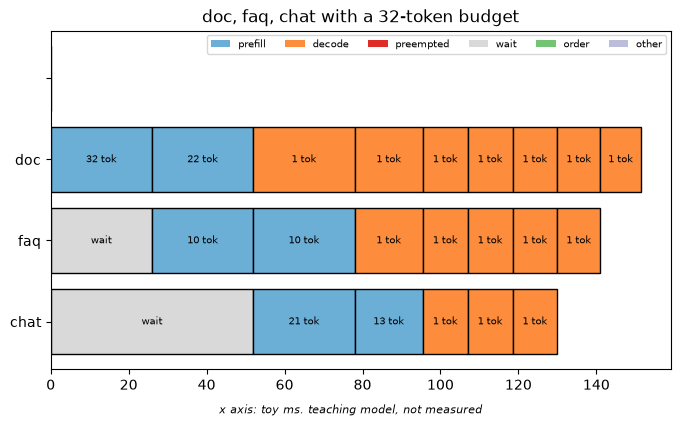

In [6]:
view.timeline([LEGEND_ROW, *spans], title="doc, faq, chat with a 32-token budget", x_label="",
              note="x axis: toy ms. teaching model, not measured")

**왜 이렇게 설계했나.** 이슈 #8779("vLLM's V1 Engine Architecture")는 스케줄링이 공짜가 아니라는 점과 prefix caching을 일급 기능으로 둔다는 점을 밝힙니다. 다만 이슈에 수치가 없어 효과의 근거로는 쓰지 않습니다. [vllm/v1/core/sched/scheduler.py:593](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L593)의 주석은 이 틀 하나로 긴 프롬프트 나누기, 캐시 적중, draft token이 모두 설명된다고 적습니다. 계산 수가 전체 수를 쫓는다는 한 줄이면 캐시 적중은 "계산 수가 처음부터 앞서 있는 경우"가 되고 draft는 "전체 수가 잠깐 늘어난 경우"가 됩니다. 뒤의 해석 문장은 수업의 정리이고, 코드 주석이 직접 쓴 것은 포함된다는 사실까지입니다.

## 2. 프로세스 경계 (8분)

**개념.** 프로세스는 세 종류입니다(P1-03).

- **API server**: HTTP를 받고, 입력을 token으로 바꾸고, 출력 token을 글자로 되돌립니다. 기본 1개입니다.
- **EngineCore**: scheduler와 KV 관리를 쥐고 busy loop를 돌립니다. DP rank마다 1개입니다.
- **GPU worker**: weight를 올리고 forward를 돌립니다. GPU마다 1개입니다. 단 GPU가 하나뿐이면 executor가 `UniProcExecutor`이고 worker가 EngineCore 프로세스 안에서 돌아갑니다(P1-07).

앞의 둘 사이 통신 수단은 ZMQ입니다. 그래서 정거장 3과 7의 객체는 직렬화할 수 있는 구조체로 정의돼 있습니다([vllm/v1/engine/__init__.py:110](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/__init__.py#L110)).

**공식 문서.** [docs/design/arch_overview.md:67](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/arch_overview.md#L67) 절이 이 구조를 설명합니다. [docs/design/arch_overview.md:91](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/arch_overview.md#L91)은 worker 수를 말하는데, 이 줄은 아래 `문서와 코드가 다를 때` 표에서 다시 봅니다.

**코드.** API server 안에서 경계를 만드는 객체는 `AsyncLLM`입니다. 생성자가 차례로 네 가지를 만듭니다(P1-04).

| 무엇 | 역할 | 코드 |
|---|---|---|
| renderer | chat template 렌더링 | [vllm/v1/engine/async_llm.py:158](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/async_llm.py#L158) |
| `InputProcessor` | `EngineInput`을 `EngineCoreRequest`로 | [vllm/v1/engine/async_llm.py:161](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/async_llm.py#L161) |
| `OutputProcessor` | `EngineCoreOutputs`를 `RequestOutput`으로 | [vllm/v1/engine/async_llm.py:171](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/async_llm.py#L171) |
| EngineCore client | ZMQ로 EngineCore와 통신 | [vllm/v1/engine/async_llm.py:184](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/async_llm.py#L184) |

`make_async_mp_client`([vllm/v1/engine/core_client.py:137](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core_client.py#L137))는 DP가 없으면 `AsyncMPClient`, DP가 있고 external LB면 `DPAsyncMPClient`, 그 밖은 `DPLBAsyncMPClient`를 돌려줍니다(P1-17). API server가 한 개이면 부모 `MPClient`([vllm/v1/engine/core_client.py:583](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core_client.py#L583))의 생성자에서 EngineCore 프로세스가 생깁니다([vllm/v1/engine/core_client.py:682](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core_client.py#L682)). API server가 둘 이상이거나(내부 LB의 DP 기본값이 그렇습니다) Rust frontend이면 `run_multi_api_server`가 먼저 띄우고([vllm/entrypoints/cli/serve.py:336](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/cli/serve.py#L336)) client는 주소만 받습니다([vllm/v1/engine/core_client.py:630](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core_client.py#L630)). 새 프로세스의 시작 함수는 `EngineCoreProc.run_engine_core`([vllm/v1/engine/utils.py:283](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/utils.py#L283))입니다.

EngineCore는 worker가 몇 개이고 어디 있는지 모릅니다(P1-09). executor의 `collective_rpc`에 메서드 이름만 넘깁니다. `UniProcExecutor`의 `collective_rpc`([vllm/v1/executor/uniproc_executor.py:90](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/executor/uniproc_executor.py#L90))는 같은 프로세스의 worker를 바로 부르고, `rpc_broadcast_mq`([vllm/v1/executor/multiproc_executor.py:164](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/executor/multiproc_executor.py#L164))를 쓰는 쪽은 공유 메모리 queue로 모든 worker에 같은 호출을 뿌립니다. 그래서 `step` 코드가 GPU 수와 무관하게 같습니다.

EngineCore 하나에 딸린 worker 수가 `world_size`이고 계산은 [vllm/config/parallel.py:945](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/parallel.py#L945)에 있습니다. PP, TP, PCP의 곱이고 DP는 곱하지 않습니다(P1-08). 수업 서버 구성값은 `Day07/README.md`의 H200 SXM 4장, TP4 + MTP(5)입니다(R-02, R-07). 명령으로는 `--tensor-parallel-size 4`와 `--speculative-config '{"method":"mtp","num_speculative_tokens":5}'`입니다. 레시피 기본은 8장 TP8이므로 수업 구성은 레시피 기본이 아닙니다. 레시피의 TP4 예시는 `--kv-cache-dtype fp8`도 쓰지만(레시피 77행) 수업 README에는 KV dtype이 없고, 레시피는 Hopper를 BF16 KV로 돌리라고 따로 적습니다(레시피 88-90행). 그래서 수업 서버의 KV dtype은 이 자료로 확인되지 않았습니다(R-02).

In [7]:
def world_size(pp: int, tp: int, pcp: int) -> int:
    # vllm/config/parallel.py의 곱셈을 그대로 옮긴 지역 함수. DP는 인자에 없다.
    return pp * tp * pcp


configs = [
    ("GPU 1장", 1, 1, 1, 1),
    ("수업 서버 구성값 TP4", 1, 4, 1, 1),
    ("레시피 기본 TP8", 1, 8, 1, 1),
    ("TP4에 DP 2", 1, 4, 1, 2),
]
rows = []
for name, pp, tp, pcp, dp in configs:
    ws = world_size(pp, tp, pcp)
    rows.append({
        "구성": name, "PP": pp, "TP": tp, "PCP": pcp, "DP": dp,
        "EngineCore 수": dp,
        "EngineCore당 worker(world_size)": ws,
        "전체 worker": ws * dp,
        "한 노드의 기본 executor": "UniProcExecutor" if ws * dp == 1 else "MultiprocExecutor",
    })
view.table(rows)

,구성,PP,TP,PCP,DP,EngineCore 수,EngineCore당 worker(world_size),전체 worker,한 노드의 기본 executor
0,GPU 1장,1,1,1,1,1,1,1,UniProcExecutor
1,수업 서버 구성값 TP4,1,4,1,1,1,4,4,MultiprocExecutor
2,레시피 기본 TP8,1,8,1,1,1,8,8,MultiprocExecutor
3,TP4에 DP 2,1,4,1,2,2,4,8,MultiprocExecutor


**관찰할 것.** DP가 있는 마지막 행에서 `EngineCore당 worker`와 `전체 worker`를 비교하세요. DP는 어느 칸의 곱에 들어가고 어느 칸의 곱에는 안 들어갑니까? 네 행의 `한 노드의 기본 executor` 칸이 어떤 숫자를 보고 갈리는지도 말해 보세요. 기본 백엔드를 고르는 줄은 [vllm/config/parallel.py:1035](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/parallel.py#L1035)입니다.

In [8]:
view.table([
    {"프로세스": "API server", "개수": "기본 1", "쥐고 있는 것": "AsyncLLM, renderer, InputProcessor, OutputProcessor, 결과 queue",
     "하는 일": "HTTP, tokenize, detokenize, stop string, SSE", "맡지 않는 일": "block 배정, forward"},
    {"프로세스": "EngineCore", "개수": "DP rank마다 1", "쥐고 있는 것": "Scheduler, KV cache 관리, executor",
     "하는 일": "schedule, 결과 반영, 종료 판정, block 반납", "맡지 않는 일": "detokenize, stop string 검사, worker 위치 관리"},
    {"프로세스": "GPU worker", "개수": "GPU마다 1", "쥐고 있는 것": "weight, KV 값, model runner",
     "하는 일": "forward, sampling", "맡지 않는 일": "HTTP, 대기 queue 관리"},
])

,프로세스,개수,쥐고 있는 것,하는 일,맡지 않는 일
0,API server,기본 1,"AsyncLLM, renderer, InputProcessor, OutputProcessor, 결과 queue","HTTP, tokenize, detokenize, stop string, SSE","block 배정, forward"
1,EngineCore,DP rank마다 1,"Scheduler, KV cache 관리, executor","schedule, 결과 반영, 종료 판정, block 반납","detokenize, stop string 검사, worker 위치 관리"
2,GPU worker,GPU마다 1,"weight, KV 값, model runner","forward, sampling","HTTP, 대기 queue 관리"


마지막 칸은 수업이 코드를 읽어 정리한 경계입니다. 어떤 일을 어느 프로세스에서 찾아야 하는지를 이 칸으로 가늠합니다. 종료 판정이 어떻게 나뉘는지는 절 4에서 코드로 확인합니다.

API server가 몇 개 뜨는지는 모드마다 다릅니다(P1-11). 기본은 1이고, 내부 LB의 DP면 DP 크기, hybrid LB면 로컬 DP 크기, multi-port와 external LB와 Rust frontend면 1입니다([vllm/entrypoints/cli/serve.py:110](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/cli/serve.py#L110)부터 이어지는 주석과 분기). 공식 문서 [docs/design/arch_overview.md:75](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/arch_overview.md#L75)는 이 중 DP 경우를 말합니다.

### 문서와 코드가 다를 때

| 문서가 말하는 것 | 코드가 말하는 것 | 근거 |
|---|---|---|
| `AsyncLLMEngine`의 코드는 `vllm/engine/async_llm_engine.py`에 있다([docs/design/arch_overview.md:134](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/arch_overview.md#L134) 절의 안내) | 그 파일은 별칭 한 줄([vllm/engine/async_llm_engine.py:6](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/engine/async_llm_engine.py#L6))이다. 구현은 `vllm/v1/engine/async_llm.py`이다. `LLMEngine`도 별칭 한 줄이다([vllm/engine/llm_engine.py:6](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/engine/llm_engine.py#L6)). **코드가 맞다** | P1-05 |
| worker 수는 `tensor_parallel_size x pipeline_parallel_size`이다([docs/design/arch_overview.md:91](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/arch_overview.md#L91), [vllm/config/parallel.py:371](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/parallel.py#L371)의 docstring) | `world_size`([vllm/config/parallel.py:945](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/parallel.py#L945))는 PCP까지 곱하고 `world_size` 단언([vllm/v1/executor/multiproc_executor.py:126](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/executor/multiproc_executor.py#L126))이 이를 확인한다. **코드가 맞다** | P1-08 |

**왜 이렇게 설계했나.** 분리의 출발점은 RFC인 이슈 #6797("Isolate OpenAI Server Into Separate Process")입니다. 통신 수단은 PR #6883의 표가 보여 줍니다. Llama-3-8B-Instruct, 1xH100, 10 QPS 조건에서 `grpc`는 TPOT 64.15, TTFT 450.05이고 `zmq + pickle`은 57.35, 298.09로 둘 다 짧습니다. 이것은 그 PR 작성자가 그 조건에서 잰 값이고 이 수업의 모델과 구성에 옮길 수 없습니다. PR #17546은 `--api-server-count`로 API server 수를 engine 수와 따로 정하게 합니다. 효과 수치는 대조하지 않았으므로 쓰지 않습니다. PR #9826은 EngineCoreClient와 stop string 감지 뒤 abort를 말할 뿐, 그 본문만으로 EngineCore를 프로세스로 분리한 PR이라고 말할 수는 없습니다. 구조 자체는 위 코드로 확인한 사실입니다.

## 3. 서버 초기화 순서 (11분)

요청이 지나갈 길은 서버가 시작할 때 만들어집니다. 프로세스와 소켓과 KV 크기가 여기서 정해지므로, 순서를 알면 시작 실패 로그를 읽는 법이 달라집니다.

**먼저 예측하세요.** 포트 bind, 엔진 초기화, HTTP route 등록 중 무엇이 가장 먼저입니까? 무엇이 가장 나중입니까? 왜 그렇다고 생각하는지 한 문장으로 적으세요.

In [9]:
init_order = view.table([
    {"순서": 1, "함수": "ServeSubcommand.cmd", "프로세스": "API server", "하는 일": "실행 모드를 고른다", "줄": "vllm/entrypoints/cli/serve.py:54", "무거운 초기화": False},
    {"순서": 2, "함수": "setup_server, create_server_socket", "프로세스": "API server", "하는 일": "인자 검사, 소켓 bind", "줄": "vllm/entrypoints/launchers/launcher.py:378", "무거운 초기화": False},
    {"순서": 3, "함수": "from_cli_args, create_engine_config", "프로세스": "API server", "하는 일": "CLI 인자에서 VllmConfig로", "줄": "vllm/engine/arg_utils.py:2205", "무거운 초기화": False},
    {"순서": 4, "함수": "AsyncLLM.from_vllm_config", "프로세스": "API server", "하는 일": "renderer, 입출력 처리기, client 생성 시작", "줄": "vllm/entrypoints/launchers/api_server/entry.py:95", "무거운 초기화": False},
    {"순서": 5, "함수": "MPClient.__init__", "프로세스": "API server", "하는 일": "입력 ROUTER, 출력 PULL 소켓 bind", "줄": "vllm/v1/engine/core_client.py:660", "무거운 초기화": False},
    {"순서": 6, "함수": "launch_core_engines", "프로세스": "API server", "하는 일": "handshake ROUTER 후 EngineCore 프로세스 시작", "줄": "vllm/v1/engine/utils.py:1198", "무거운 초기화": False},
    {"순서": 7, "함수": "_perform_handshakes", "프로세스": "EngineCore", "하는 일": "HELLO를 보내고 소켓 주소를 받는다", "줄": "vllm/v1/engine/core.py:1363", "무거운 초기화": False},
    {"순서": 8, "함수": "EngineCore.__init__, executor_class", "프로세스": "EngineCore", "하는 일": "executor를 만든다", "줄": "vllm/v1/engine/core.py:144", "무거운 초기화": True},
    {"순서": 9, "함수": "init_device, load_model", "프로세스": "GPU worker", "하는 일": "메모리 예산 계산, weight 적재", "줄": "vllm/v1/worker/gpu_worker.py:436", "무거운 초기화": True},
    {"순서": 10, "함수": "determine_available_memory, profile_run", "프로세스": "GPU worker", "하는 일": "dummy 입력으로 activation 최고치 측정", "줄": "vllm/v1/worker/gpu_worker.py:634", "무거운 초기화": True},
    {"순서": 11, "함수": "initialize_from_config, compile_or_warm_up_model", "프로세스": "EngineCore에서 worker로", "하는 일": "KV cache 준비, warm-up", "줄": "vllm/v1/engine/core.py:377", "무거운 초기화": True},
    {"순서": 12, "함수": "Scheduler(...)", "프로세스": "EngineCore", "하는 일": "scheduler 생성", "줄": "vllm/v1/engine/core.py:174", "무거운 초기화": False},
    {"순서": 13, "함수": "handshake context 종료", "프로세스": "EngineCore", "하는 일": "입출력 thread 시작 후 READY 전송", "줄": "vllm/v1/engine/core.py:1340", "무거운 초기화": False},
    {"순서": 14, "함수": "run_busy_loop", "프로세스": "EngineCore", "하는 일": "입력 queue를 비우고 step을 되풀이", "줄": "vllm/v1/engine/core.py:1547", "무거운 초기화": False},
    {"순서": 15, "함수": "build_and_serve, build_app, init_app_state", "프로세스": "API server", "하는 일": "FastAPI 앱, route, handler 준비", "줄": "vllm/entrypoints/launchers/api_server/entry.py:116", "무거운 초기화": False},
    {"순서": 16, "함수": "serve_http, NoSignalServer", "프로세스": "API server", "하는 일": "Uvicorn을 띄워 bind한 소켓으로 서빙", "줄": "vllm/entrypoints/launchers/launcher.py:175", "무거운 초기화": False},
])
init_order

,순서,함수,프로세스,하는 일,줄,무거운 초기화
0,1,ServeSubcommand.cmd,API server,실행 모드를 고른다,vllm/entrypoints/cli/serve.py:54,False
1,2,"setup_server, create_server_socket",API server,"인자 검사, 소켓 bind",vllm/entrypoints/launchers/launcher.py:378,False
2,3,"from_cli_args, create_engine_config",API server,CLI 인자에서 VllmConfig로,vllm/engine/arg_utils.py:2205,False
3,4,AsyncLLM.from_vllm_config,API server,"renderer, 입출력 처리기, client 생성 시작",vllm/entrypoints/launchers/api_server/entry.py:95,False
4,5,MPClient.__init__,API server,"입력 ROUTER, 출력 PULL 소켓 bind",vllm/v1/engine/core_client.py:660,False
5,6,launch_core_engines,API server,handshake ROUTER 후 EngineCore 프로세스 시작,vllm/v1/engine/utils.py:1198,False
6,7,_perform_handshakes,EngineCore,HELLO를 보내고 소켓 주소를 받는다,vllm/v1/engine/core.py:1363,False
7,8,"EngineCore.__init__, executor_class",EngineCore,executor를 만든다,vllm/v1/engine/core.py:144,True
8,9,"init_device, load_model",GPU worker,"메모리 예산 계산, weight 적재",vllm/v1/worker/gpu_worker.py:436,True
9,10,"determine_available_memory, profile_run",GPU worker,dummy 입력으로 activation 최고치 측정,vllm/v1/worker/gpu_worker.py:634,True


**표의 `줄` 칸 원문 링크.** [vllm/entrypoints/cli/serve.py:54](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/cli/serve.py#L54) · [vllm/entrypoints/launchers/launcher.py:378](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/launchers/launcher.py#L378) · [vllm/engine/arg_utils.py:2205](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/engine/arg_utils.py#L2205) · [vllm/entrypoints/launchers/api_server/entry.py:95](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/launchers/api_server/entry.py#L95) · [vllm/v1/engine/core_client.py:660](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core_client.py#L660) · [vllm/v1/engine/utils.py:1198](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/utils.py#L1198) · [vllm/v1/engine/core.py:1363](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core.py#L1363) · [vllm/v1/engine/core.py:144](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core.py#L144) · [vllm/v1/worker/gpu_worker.py:436](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu_worker.py#L436) · [vllm/v1/worker/gpu_worker.py:634](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu_worker.py#L634) · [vllm/v1/engine/core.py:377](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core.py#L377) · [vllm/v1/engine/core.py:174](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core.py#L174) · [vllm/v1/engine/core.py:1340](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core.py#L1340) · [vllm/v1/engine/core.py:1547](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core.py#L1547) · [vllm/entrypoints/launchers/api_server/entry.py:116](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/launchers/api_server/entry.py#L116) · [vllm/entrypoints/launchers/launcher.py:175](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/launchers/launcher.py#L175)

**공식 문서.** 이 호출 순서를 줄 단위로 설명한 공식 문서는 찾지 못했습니다. 아래는 코드를 따라 읽은 것이고, 여섯 구간으로 나눠 걷습니다.

**구간 1, 모드 선택.** `vllm serve`를 받는 `ServeSubcommand.cmd`([vllm/entrypoints/cli/serve.py:54](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/cli/serve.py#L54))가 실행 모드를 고릅니다(P1-10). 맨 앞에 `serve_grpc`([vllm/entrypoints/cli/serve.py:60](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/cli/serve.py#L60))로 가는 `--grpc` 분기가 있고, 그 뒤 `if is_multi_port`([vllm/entrypoints/cli/serve.py:147](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/cli/serve.py#L147))에서 시작하는 분기가 `run_dp_supervisor`, `run_headless`, `run_multi_api_server`를 가립니다. 어디에도 걸리지 않으면 이 프로세스에서 `run_server`를 uvloop로 돌립니다. 지금부터는 이 마지막 경로만 봅니다.

**구간 2, 소켓 bind.** `run_server`([vllm/entrypoints/launchers/api_server/entry.py:165](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/launchers/api_server/entry.py#L165)) 안의 두 줄이 이 절의 핵심입니다. `setup_server`([vllm/entrypoints/launchers/api_server/entry.py:176](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/launchers/api_server/entry.py#L176))가 먼저 소켓을 잡고, 바로 다음 줄 `run_server_worker`([vllm/entrypoints/launchers/api_server/entry.py:177](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/launchers/api_server/entry.py#L177))가 그 소켓을 들고 엔진을 만들러 갑니다. 실제 bind는 `sock.bind`([vllm/entrypoints/launchers/launcher.py:348](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/launchers/launcher.py#L348))입니다.

`setup_server`가 하는 일은 여기까지입니다. 소켓은 나중에 `serve_http`로 넘어가고, listen이 걸리는 위치는 경로마다 다릅니다(P1-12, 코드 읽기). API server가 한 개이고 `peer_loads`가 없는 이 경로에서는 `NoSignalServer.startup`([vllm/entrypoints/launchers/launcher.py:82](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/launchers/launcher.py#L82))이 `super().startup(sockets)`로 소켓을 Uvicorn에 넘깁니다([vllm/entrypoints/launchers/launcher.py:84](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/launchers/launcher.py#L84)). 이 자료가 읽은 Uvicorn 0.54.0은 `server.py` 154줄 근처에서 `loop.create_server(sock=...)`를 부르고, listen은 그 안에서 걸린다고 읽었습니다. 여러 API server가 소켓을 공유하는 경로(`peer_loads`가 있을 때, [vllm/entrypoints/launchers/api_server/entry.py:190-193](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/launchers/api_server/entry.py#L190-L193))에서는 vLLM이 직접 `sock.listen`을 부릅니다([vllm/entrypoints/launchers/launcher.py:92](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/launchers/launcher.py#L92)). 블로그 그림이 기준으로 삼은 Uvicorn 0.52.4는 읽지 않았습니다.

**구간 3, 설정.** `AsyncEngineArgs.from_cli_args`([vllm/entrypoints/launchers/api_server/entry.py:53](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/launchers/api_server/entry.py#L53))는 이름이 같은 값만 옮깁니다([vllm/engine/arg_utils.py:1933](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/engine/arg_utils.py#L1933)). 기본값 결정과 검증은 `create_engine_config`([vllm/entrypoints/launchers/api_server/entry.py:83](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/launchers/api_server/entry.py#L83))에서 일어나고 그 결과가 `VllmConfig`입니다(P1-15). `max_num_batched_tokens` 기본값도 여기서 GPU 메모리와 진입점을 보고 정해집니다(P1-16). 숫자는 03에서 다룹니다. A100만 작게 잡는 예외는 [vllm/engine/arg_utils.py:2920](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/engine/arg_utils.py#L2920)의 주석에 PR #17885로 남아 있습니다.

**구간 4, client와 handshake.** `AsyncLLM.from_vllm_config`([vllm/entrypoints/launchers/api_server/entry.py:95](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/launchers/api_server/entry.py#L95))가 `AsyncLLM`을 만들면 절 2의 client 생성이 일어납니다. `MPClient`는 먼저 입력용 ROUTER와 출력용 PULL을 bind합니다([vllm/v1/engine/core_client.py:660](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core_client.py#L660)). 그다음 `launch_core_engines`([vllm/v1/engine/core_client.py:682](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core_client.py#L682))의 `with` 블록으로 들어갑니다(P1-18). `zmq_socket_ctx`([vllm/v1/engine/utils.py:1327](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/utils.py#L1327))가 handshake용 ROUTER를 열고 EngineCore 프로세스를 띄웁니다.

대화는 세 번 오갑니다(P1-19).

| 차례 | 보내는 쪽 | 내용 | 코드 |
|---:|---|---|---|
| 1 | EngineCore | HELLO | [vllm/v1/engine/core.py:1363](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core.py#L1363) 전송, [vllm/v1/engine/utils.py:1475](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/utils.py#L1475) 수신 |
| 2 | client | ZMQ 입출력 소켓 주소 | HELLO를 받은 분기 안에서 돌려준다 |
| 3 | EngineCore | READY | [vllm/v1/engine/core.py:1340](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core.py#L1340) 전송, [vllm/v1/engine/utils.py:1498](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/utils.py#L1498) 수신 |

client 쪽 대기는 `with` 블록을 벗어나는 순간 `wait_for_engine_startup`([vllm/v1/engine/utils.py:1351](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/utils.py#L1351))에서 일어납니다. 이 대기에는 시간 한도가 없습니다. handshake 소켓과 프로세스 종료 신호를 함께 기다리므로([vllm/v1/engine/utils.py:1385](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/utils.py#L1385)) 프로세스가 죽으면 바로 깨어나 오류를 내고([vllm/v1/engine/utils.py:1431](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/utils.py#L1431)), 아무 일 없이 10초가 지나면 debug 로그만 남기고 다시 기다립니다([vllm/v1/engine/utils.py:1398](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/utils.py#L1398)). `VLLM_ENGINE_READY_TIMEOUT_S`([vllm/envs.py:26](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/envs.py#L26), 기본 600초)가 걸리는 곳은 입력 소켓으로 오는 등록 메시지를 기다리는 [vllm/v1/engine/core_client.py:740](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core_client.py#L740)입니다. EngineCore는 무거운 초기화를 끝낸 뒤 READY보다 먼저 이 메시지를 보내므로([vllm/v1/engine/core.py:1877](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core.py#L1877)), 지금 보는 경로에서는 이 대기가 weight 적재 시간을 재지 않습니다. 엔진이 끝나기 전에 frontend를 먼저 띄우는 경로는 다릅니다. 레시피가 켜는 Rust frontend가 그렇습니다. Python이 `with` 블록 안에서 Rust 프로세스를 띄우고([vllm/entrypoints/cli/serve.py:354](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/cli/serve.py#L354)), Rust 쪽이 같은 값으로 이 메시지를 기다립니다([rust/src/engine-core-client/src/transport.rs:516](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/rust/src/engine-core-client/src/transport.rs#L516)). 이 Rust 쪽 설명은 코드를 읽은 것이고 실행해 확인하지는 않았습니다. 레시피 명령은 이 값을 3600으로 올리고(P1-51) weight는 약 306 GiB로 적으니(R-06), 그 경로에서는 기본값이 모자랄 수 있습니다(수업의 해석).

**구간 5, EngineCore 초기화.** 무거운 엔진 초기화는 HELLO와 READY 사이에서 일어납니다. 이 구간은 `_perform_handshakes`([vllm/v1/engine/core.py:1164](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core.py#L1164))의 context 안입니다(P1-20). `EngineCore.__init__`의 순서는 executor, KV cache, scheduler입니다(P1-06).

1. `executor_class(vllm_config)`([vllm/v1/engine/core.py:144](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core.py#L144))가 worker를 만듭니다. worker는 `init_device`([vllm/v1/worker/gpu_worker.py:436](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu_worker.py#L436))에서 메모리 예산을 정합니다. 예산은 `gpu_memory_utilization` × GPU 전체 메모리입니다([vllm/v1/worker/utils.py:725](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/utils.py#L725), P1-21). 비율 기본값은 0.92입니다([vllm/config/cache.py:102](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/cache.py#L102))(D-03). 연산 사용률이 아니라 메모리 비율입니다. 이어서 `load_model`([vllm/v1/worker/gpu_worker.py:587](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu_worker.py#L587))이 weight를 적재합니다.
2. `_initialize_kv_caches` 호출([vllm/v1/engine/core.py:157](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core.py#L157))이 그 정의([vllm/v1/engine/core.py:261](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core.py#L261))로 들어갑니다. `determine_available_memory` 호출([vllm/v1/engine/core.py:315](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core.py#L315))이 `collective_rpc`로 worker를 부르면, worker는 `determine_available_memory`([vllm/v1/worker/gpu_worker.py:634](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu_worker.py#L634))에서 `profile_run`([vllm/v1/worker/gpu_worker.py:693](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu_worker.py#L693))을 돌립니다(P1-22). `profile_run`([vllm/v1/worker/gpu/model_runner.py:991](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/model_runner.py#L991))은 최대 token 수(`max_num_batched_tokens`) 크기의 dummy 입력을 돌려 activation 최고치를 잽니다. 이어서 `profile_cudagraph_memory`([vllm/v1/worker/gpu_worker.py:704](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu_worker.py#L704))가 CUDA graph 메모리를 추정합니다.
3. 남은 메모리로 KV cache 설정을 만든 뒤 `initialize_from_config`([vllm/v1/engine/core.py:377](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core.py#L377))와 `compile_or_warm_up_model`([vllm/v1/engine/core.py:379](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core.py#L379))을 부릅니다.
4. `Scheduler(...)`([vllm/v1/engine/core.py:174](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core.py#L174))를 만듭니다.
5. 입출력 thread를 띄우고 context를 빠져나오며 READY를 보낸 뒤, `run_busy_loop` 호출([vllm/v1/engine/core.py:1496](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core.py#L1496))로 들어갑니다. `run_busy_loop`([vllm/v1/engine/core.py:1547](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core.py#L1547))의 본문은 입력 queue를 비우고 step을 한 번 도는 일의 되풀이입니다.

KV 크기가 시작할 때 실제로 모델을 돌려 본 결과로 정해진다는 점이 중요합니다. 기본 설정에서는 숫자를 설정 파일에서 읽지 않습니다. 예외는 `--kv-cache-memory-bytes`입니다. 이 값을 주면 `determine_available_memory`는 `profile_run`을 돌리기는 하지만 그 결과로 메모리를 재지 않고 이 값을 KV 크기로 쓰며, `gpu_memory_utilization`도 따르지 않습니다([vllm/v1/worker/gpu_worker.py:649](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu_worker.py#L649)). `gpu_memory_utilization`은 전체 예산만 정합니다.

**구간 6, HTTP.** READY를 받은 뒤에야 `build_and_serve`([vllm/entrypoints/launchers/api_server/entry.py:116](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/launchers/api_server/entry.py#L116))가 불립니다(P1-14, P1-25). `build_app`([vllm/entrypoints/launchers/app.py:19](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/launchers/app.py#L19))이 FastAPI 앱을 만들고 `register_api_routers`([vllm/entrypoints/launchers/app.py:45](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/launchers/app.py#L45))가 지원 task에 맞는 route만 붙입니다([vllm/entrypoints/launchers/api_server/routers.py:49](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/launchers/api_server/routers.py#L49)). `init_app_state`([vllm/entrypoints/launchers/api_server/entry.py:138](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/launchers/api_server/entry.py#L138))가 `OpenAIServingChat` 같은 handler를 `app.state`에 만들고, `serve_http`([vllm/entrypoints/launchers/launcher.py:175](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/launchers/launcher.py#L175))가 `NoSignalServer`([vllm/entrypoints/launchers/launcher.py:225](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/launchers/launcher.py#L225))로 Uvicorn을 띄웁니다. `server.serve`([vllm/entrypoints/launchers/launcher.py:236](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/launchers/launcher.py#L236))에 넘기는 소켓이 구간 2에서 잡아 둔 그 소켓입니다.

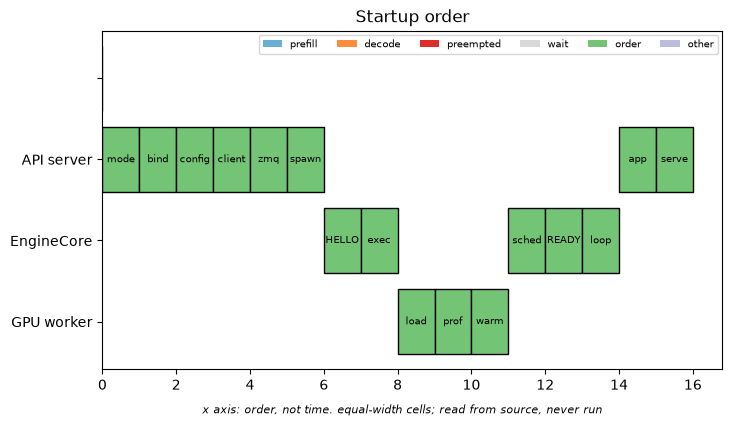

In [10]:
order_cells = [
    ("API server", "mode"), ("API server", "bind"), ("API server", "config"), ("API server", "client"),
    ("API server", "zmq"), ("API server", "spawn"), ("EngineCore", "HELLO"), ("EngineCore", "exec"),
    ("GPU worker", "load"), ("GPU worker", "prof"), ("GPU worker", "warm"), ("EngineCore", "sched"),
    ("EngineCore", "READY"), ("EngineCore", "loop"), ("API server", "app"), ("API server", "serve"),
]
order_spans = [
    {"lane": lane, "start": i, "end": i + 1, "label": label, "kind": "order"}
    for i, (lane, label) in enumerate(order_cells)
]
view.timeline([LEGEND_ROW, *order_spans], title="Startup order", x_label="",
              note="x axis: order, not time. equal-width cells; read from source, never run")

칸 너비는 모두 같습니다. **시간이 아니라 순서입니다.** 이 소스로 서버를 띄운 적이 없으므로 구간별 소요 시간은 이 자료에 없습니다. 실제 기동이 얼마나 걸리는지는 `2026-09-15 강사 메모, v0.28 dev`에 15~20분으로 적혀 있습니다(`Day07/README.md:80`). 버전이 다른 빌드에서 한 번 잰 메모입니다.

### 문서와 코드가 다를 때

| 문서가 말하는 것 | 코드가 말하는 것 | 근거 |
|---|---|---|
| worker 주석은 CUDA graph 추정을 "opt-in"이라고 적는다([vllm/v1/worker/gpu_worker.py:706](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu_worker.py#L706)). PR #30515 본문도 기본 꺼짐이라고 쓴다 | 환경변수 `VLLM_MEMORY_PROFILER_ESTIMATE_CUDAGRAPHS`의 기본값은 `True`([vllm/envs.py:328](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/envs.py#L328))로 켜져 있다. **값이 맞고 주석이 낡았다** | P1-23 |

**실패 재현.** 포트가 이미 잡혀 있으면 어떻게 되는지 봅니다. 같은 포트를 소켓 두 개로 `bind`합니다. 접속은 하지 않습니다. 실제 코드는 bind 전에 옵션을 켜지만([vllm/entrypoints/launchers/launcher.py:345](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/launchers/launcher.py#L345)), 이 재현은 현상만 보려고 옵션 없이 씁니다.

In [11]:
# 실패 재현: 같은 포트를 두 번 bind
host = "localhost"
first = socket.socket(socket.AF_INET, socket.SOCK_STREAM)
second = socket.socket(socket.AF_INET, socket.SOCK_STREAM)
try:
    first.bind((host, 0))
    port = first.getsockname()[1]
    print("첫 번째 bind 성공. 운영체제가 고른 포트 번호:", port)
    second.bind((host, port))
    print("두 번째 bind도 성공")
except OSError as exc:
    print("예외 종류:", type(exc).__name__)
    print("오류 번호:", exc.errno, errno.errorcode.get(exc.errno))
    print("메시지:", exc.strerror)
finally:
    first.close()
    second.close()

첫 번째 bind 성공. 운영체제가 고른 포트 번호: 56772
예외 종류: OSError
오류 번호: 48 EADDRINUSE
메시지: Address already in use


**관찰할 것.** 출력된 오류 번호와 그 이름을 읽으세요. 이슈 #8204의 제목은 `[Errno 98]`입니다. 지금 출력된 번호가 다르다면 어느 칸이 운영체제마다 달라지고 어느 칸이 같은지 구분하세요.

이제 이 실패가 초기화 순서의 어디에서 일어나는지 셉니다. 아래 표의 두 번째 행은 **vLLM이 하지 않는 가정**입니다. 순서를 바꿨을 때를 비교하려고 만들었습니다.

In [12]:
def cost_if_bind_fails(bind_order: int) -> dict:
    done = init_order[init_order["순서"] < bind_order]
    return {"끝낸 단계 수": len(done), "끝낸 무거운 초기화 수": int(done["무거운 초기화"].sum())}


view.table([
    {"bind 위치": "실제 코드: 순서 2", **cost_if_bind_fails(2)},
    {"bind 위치": "가정: serve_http 직전(순서 16)", **cost_if_bind_fails(16)},
])

,bind 위치,끝낸 단계 수,끝낸 무거운 초기화 수
0,실제 코드: 순서 2,1,0
1,가정: serve_http 직전(순서 16),15,4


이 표는 단계 수를 센 것이고 시간이 아닙니다. 숫자의 뜻은 "실패를 알기까지 weight를 올리고 profiling을 돌렸는가"입니다.

**시작 로그 읽기.** 구간 5의 2번 profiling이 끝나면, 3번의 `initialize_from_config`로 넘어가기 전에 EngineCore가 KV 용량을 한 줄로 남깁니다(`update_kv_cache_capacity` 호출 [vllm/v1/engine/core.py:357](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core.py#L357)). 그래서 이 줄이 보여도 warm-up과 scheduler 생성은 아직 남아 있습니다. 실제 형식은 [vllm/v1/core/kv_cache_utils.py:2328](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L2328)에 있습니다.

```text
GPU KV cache size: N tokens, Maximum concurrency for M tokens per request: X.XXx
```

세 숫자는 독립이 아닙니다. `N`은 반올림 전 동시성에 `M`을 곱한 값입니다([vllm/v1/core/kv_cache_utils.py:2308](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L2308)). 로그의 `X.XX`는 소수 둘째 자리로 반올림한 값이므로 `N / M`을 반올림하면 `X.XX`가 나와야 합니다. PDF 1장의 시작 로그는 스스로 설명용이라고 밝힌 예시인데, 세 숫자가 이 관계를 만족하지 않습니다(D-02). 아래 셀은 산수이고 측정이 아닙니다.

In [13]:
log_line = "GPU KV cache size: {:,} tokens, Maximum concurrency for {:,} tokens per request: {:.2f}x"

rows = [
    {"경우": "PDF 예시", "M(max_model_len)": 64000, "로그의 N": 65536, "로그의 X": 8.00},
    {"경우": "M만 바꾼 예시", "M(max_model_len)": 8192, "로그의 N": 65536, "로그의 X": 8.00},
]
for row in rows:
    row["N / M"] = round(row["로그의 N"] / row["M(max_model_len)"], 2)
    row["맞는가"] = row["N / M"] == row["로그의 X"]
print(log_line.format(rows[1]["로그의 N"], rows[1]["M(max_model_len)"], rows[1]["로그의 X"]))
view.table(rows)

GPU KV cache size: 65,536 tokens, Maximum concurrency for 8,192 tokens per request: 8.00x


,경우,M(max_model_len),로그의 N,로그의 X,N / M,맞는가
0,PDF 예시,64000,65536,8.0,1.02,False
1,M만 바꾼 예시,8192,65536,8.0,8.00,True


**관찰할 것.** `N / M` 칸과 `로그의 X` 칸을 행별로 비교하세요. 나중에 수업 서버의 진짜 로그를 보게 되면 같은 계산으로 그 로그를 검산할 수 있습니다.

**왜 이렇게 설계했나.** bind가 먼저인 이유는 코드 주석에 있습니다. [vllm/entrypoints/launchers/launcher.py:391](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/launchers/launcher.py#L391)과 다음 줄은 Ray와의 race를 피하려는 우회라고 적고 이슈 #8204를 가리킵니다. 이슈 본문은 시작 시 address in use 실패 보고입니다. 포트 충돌이 무거운 초기화 전에 드러나는 것은 주석이 말한 목적이 아니라 호출 순서에서 따라 나오는 결과입니다(P1-13). 앞의 `bind 위치` 표가 그 결과입니다. KV 크기를 스스로 정하는 기능은 PR #6("Automatically configure KV cache size", 2023-03-12 병합, P1-24)까지 올라갑니다. 이 노트북은 그 PR의 제목과 병합일까지만 확인했으므로 그 PR이 밝힌 이유를 여기에 옮기지 않습니다. CUDA graph 메모리를 profiling에 넣은 것은 PR #30515이고 처음에는 기본 꺼짐이었습니다. `NoSignalServer`의 이유는 [vllm/entrypoints/launchers/launcher.py:45](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/launchers/launcher.py#L45)의 docstring과 PR #49668에 있습니다. Uvicorn이 signal handler를 설치하면 앱이 등록한 종료 handler와 race가 난다는 것입니다(P1-26). 레시피가 `VLLM_ENGINE_READY_TIMEOUT_S`를 600초에서 3600으로 올리는 것은, 레시피가 켜는 Rust frontend가 엔진 초기화가 끝나기를 이 값으로 기다리기 때문이라고 읽을 수 있습니다(수업의 해석, 코드를 읽은 것이며 실행해 확인하지 않았습니다, P1-51). profiling이 시작 시간을 얼마나 늘리는지 잰 수치는 이 자료에 없습니다.

## 4. request 경로와 객체 사슬 (11분)

**개념.** 요청은 프로세스와 층을 지날 때마다 다른 객체로 바뀝니다. 각 객체는 그 층이 알아야 할 것만 듭니다. 아래 표가 이 노트북에서 가장 중요한 표입니다(P1-27).

**공식 문서.** 객체 사슬을 한 표로 정리한 공식 문서는 찾지 못했습니다. 코드로 확인합니다.

In [14]:
chain = view.table([
    {"순서": 1, "객체": "ChatCompletionRequest", "정의": "vllm/entrypoints/openai/chat_completion/protocol.py:220", "사는 곳": "API server",
     "만드는 곳": "FastAPI route의 본문 파싱", "만드는 코드": "vllm/entrypoints/openai/chat_completion/api_router.py:42"},
    {"순서": 2, "객체": "EngineInput", "정의": "vllm/inputs/engine.py:266", "사는 곳": "API server",
     "만드는 곳": "OnlineRenderer.render_chat", "만드는 코드": "vllm/renderers/online_renderer.py:224"},
    {"순서": 3, "객체": "EngineCoreRequest", "정의": "vllm/v1/engine/__init__.py:109", "사는 곳": "API server에서 EngineCore로",
     "만드는 곳": "InputProcessor.process_inputs", "만드는 코드": "vllm/v1/engine/async_llm.py:474"},
    {"순서": 4, "객체": "Request", "정의": "vllm/v1/request.py:60", "사는 곳": "EngineCore",
     "만드는 곳": "preprocess_add_request", "만드는 코드": "vllm/v1/engine/core.py:1089"},
    {"순서": 5, "객체": "SchedulerOutput", "정의": "vllm/v1/core/sched/output.py:232", "사는 곳": "EngineCore에서 worker로",
     "만드는 곳": "Scheduler.schedule", "만드는 코드": "vllm/v1/core/sched/scheduler.py:591"},
    {"순서": 6, "객체": "ModelRunnerOutput", "정의": "vllm/v1/outputs.py:267", "사는 곳": "worker에서 EngineCore로",
     "만드는 곳": "sample_tokens", "만드는 코드": "vllm/v1/worker/gpu/model_runner.py:2088"},
    {"순서": 7, "객체": "EngineCoreOutputs", "정의": "vllm/v1/engine/__init__.py:259", "사는 곳": "EngineCore에서 API server로",
     "만드는 곳": "update_from_output", "만드는 코드": "vllm/v1/engine/core.py:681"},
    {"순서": 8, "객체": "RequestOutput", "정의": "vllm/outputs.py:129", "사는 곳": "API server",
     "만드는 곳": "OutputProcessor.process_outputs", "만드는 코드": "vllm/v1/engine/output_processor.py:412"},
])
chain

,순서,객체,정의,사는 곳,만드는 곳,만드는 코드
0,1,ChatCompletionRequest,vllm/entrypoints/openai/chat_completion/protocol.py:220,API server,FastAPI route의 본문 파싱,vllm/entrypoints/openai/chat_completion/api_router.py:42
1,2,EngineInput,vllm/inputs/engine.py:266,API server,OnlineRenderer.render_chat,vllm/renderers/online_renderer.py:224
2,3,EngineCoreRequest,vllm/v1/engine/__init__.py:109,API server에서 EngineCore로,InputProcessor.process_inputs,vllm/v1/engine/async_llm.py:474
3,4,Request,vllm/v1/request.py:60,EngineCore,preprocess_add_request,vllm/v1/engine/core.py:1089
4,5,SchedulerOutput,vllm/v1/core/sched/output.py:232,EngineCore에서 worker로,Scheduler.schedule,vllm/v1/core/sched/scheduler.py:591
5,6,ModelRunnerOutput,vllm/v1/outputs.py:267,worker에서 EngineCore로,sample_tokens,vllm/v1/worker/gpu/model_runner.py:2088
6,7,EngineCoreOutputs,vllm/v1/engine/__init__.py:259,EngineCore에서 API server로,update_from_output,vllm/v1/engine/core.py:681
7,8,RequestOutput,vllm/outputs.py:129,API server,OutputProcessor.process_outputs,vllm/v1/engine/output_processor.py:412


**표의 코드 칸 원문 링크.** [vllm/entrypoints/openai/chat_completion/protocol.py:220](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/protocol.py#L220) · [vllm/entrypoints/openai/chat_completion/api_router.py:42](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/api_router.py#L42) · [vllm/inputs/engine.py:266](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/inputs/engine.py#L266) · [vllm/renderers/online_renderer.py:224](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/renderers/online_renderer.py#L224) · [vllm/v1/engine/__init__.py:109](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/__init__.py#L109) · [vllm/v1/engine/async_llm.py:474](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/async_llm.py#L474) · [vllm/v1/request.py:60](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/request.py#L60) · [vllm/v1/engine/core.py:1089](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core.py#L1089) · [vllm/v1/core/sched/output.py:232](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/output.py#L232) · [vllm/v1/core/sched/scheduler.py:591](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L591) · [vllm/v1/outputs.py:267](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/outputs.py#L267) · [vllm/v1/worker/gpu/model_runner.py:2088](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/model_runner.py#L2088) · [vllm/v1/engine/__init__.py:259](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/__init__.py#L259) · [vllm/v1/engine/core.py:681](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core.py#L681) · [vllm/outputs.py:129](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/outputs.py#L129) · [vllm/v1/engine/output_processor.py:412](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/output_processor.py#L412)

3번과 7번이 API server와 EngineCore 사이의 ZMQ 경계를 넘습니다. 5번과 6번은 절 2의 executor를 통해 EngineCore와 worker 사이를 오갑니다.

**코드, 정거장 1과 2.** route는 `"/v1/chat/completions"`([vllm/entrypoints/openai/chat_completion/api_router.py:42](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/api_router.py#L42))이고 생성 API route는 chat, completions, responses, anthropic messages, cohere chat 다섯 종입니다(P1-28). chat route는 `@with_cancellation`([vllm/entrypoints/openai/chat_completion/api_router.py:52](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/api_router.py#L52))과 `@load_aware_call`로 감싸입니다. handler 결과가 오류면 오류 JSON, 완성 응답이면 JSON, 그 밖은 스트림입니다(P1-29). 스트림은 `data: [DONE]`으로 끝납니다([vllm/entrypoints/openai/chat_completion/serving.py:933](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/serving.py#L933)).

handler 안의 순서는 다음과 같습니다(P1-30).

1. `render_chat_request`([vllm/entrypoints/openai/chat_completion/serving.py:258](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/serving.py#L258))가 모델 이름을 확인하고, `_preflight`([vllm/entrypoints/openai/chat_completion/serving.py:277](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/serving.py#L277))로 admission을 먼저 검사한 뒤 `online_renderer.render_chat`([vllm/entrypoints/openai/chat_completion/serving.py:279](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/serving.py#L279))에 넘깁니다. 실제 렌더링과 tokenize는 [vllm/renderers/online_renderer.py:224](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/renderers/online_renderer.py#L224) 아래에서 일어납니다. 즉 **tokenize는 API server 프로세스의 일입니다.**
2. `get_max_tokens`([vllm/entrypoints/openai/chat_completion/serving.py:343](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/serving.py#L343))가 생성 한도를 정합니다.
3. `to_sampling_params`([vllm/entrypoints/openai/chat_completion/serving.py:360](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/serving.py#L360))가 샘플링 파라미터를 만듭니다.
4. `engine_client.generate`([vllm/entrypoints/openai/chat_completion/serving.py:389](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/serving.py#L389))가 엔진으로 보냅니다.

**생성 한도.** `get_max_tokens`([vllm/entrypoints/serve/utils/api_utils.py:169](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/serve/utils/api_utils.py#L169))가 하는 일은 `fallback`을 정하고 네 항의 최솟값을 구하는 것입니다(P1-31, P1-32).

| 항 | 값 | 어디서 오나 |
|---|---|---|
| `model_max_tokens` | `max_model_len - 입력 길이` | 함수 안에서 계산 |
| `fallback_max_tokens` | 요청의 값, 없으면 서버 기본 샘플링 값 | [vllm/entrypoints/serve/utils/api_utils.py:190](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/serve/utils/api_utils.py#L190) |
| `override_max_tokens` | 생성자가 미리 고른 값 | [vllm/entrypoints/openai/chat_completion/serving.py:177](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/serving.py#L177) |
| `platform_max_tokens` | 플랫폼 한도. 기본 구현은 `sys.maxsize` | [vllm/platforms/interface.py:225](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/platforms/interface.py#L225) |

항 중 일부는 함수 밖에서 정해집니다(P1-32). 요청의 `max_completion_tokens`와 `max_tokens` 중 무엇을 넘길지는 호출하는 serving이 고르고([vllm/entrypoints/openai/chat_completion/serving.py:345-347](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/serving.py#L345-L347)), 어느 값을 `override`로 삼을지는 serving 생성자가 정하며, 서버 기본 샘플링 값은 `get_diff_sampling_param`([vllm/config/model.py:1847](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/model.py#L1847))이 합칩니다. 아래는 함수의 `fallback` 결정과 마지막 최솟값 계산만 옮긴 지역 함수이고, `max_model_len=4096`과 입력 54는 수업의 값입니다.

In [15]:
def get_max_tokens_like(max_model_len, input_length, request_max_tokens, default_max_tokens=None,
                        override_max_tokens=None, platform_max_tokens=sys.maxsize):
    # vllm/entrypoints/serve/utils/api_utils.py의 fallback 결정과 최솟값 계산만 옮긴 수업용 지역 함수.
    terms = {
        "model": max_model_len - input_length,
        "fallback": request_max_tokens if request_max_tokens is not None else default_max_tokens,
        "override": override_max_tokens,
        "platform": platform_max_tokens,
    }
    present = {name: value for name, value in terms.items() if value is not None}
    winner = min(present, key=present.get)
    return present[winner], winner


cases = [
    ("요청에 max_tokens 없음", None, None),
    ("요청이 8", 8, None),
    ("요청이 9000", 9000, None),
    ("요청이 9000, override 256", 9000, 256),
]
rows = []
for name, requested, override in cases:
    value, winner = get_max_tokens_like(4096, 54, requested, override_max_tokens=override)
    rows.append({"경우": name, "최종 max_tokens": value, "정한 항": winner})
view.table(rows)

,경우,최종 max_tokens,정한 항
0,요청에 max_tokens 없음,4042,model
1,요청이 8,8,fallback
2,요청이 9000,4042,model
3,"요청이 9000, override 256",256,override


**코드, 정거장 3과 4.** 이제 요청이 경계를 넘습니다. 순서가 중요합니다(P1-33).

In [16]:
view.table([
    {"순서": 1, "프로세스": "API server", "함수": "check_admission", "하는 일": "큐 한도를 다시 검사한다(첫 검사는 render 앞의 _preflight). 기본값은 검사하지 않는다", "줄": "vllm/v1/engine/async_llm.py:569"},
    {"순서": 2, "프로세스": "API server", "함수": "output_processor.add_request", "하는 일": "결과 queue를 먼저 등록한다", "줄": "vllm/v1/engine/async_llm.py:572"},
    {"순서": 3, "프로세스": "API server", "함수": "engine_core.add_request_async", "하는 일": "ADD message를 ZMQ로 보낸다", "줄": "vllm/v1/engine/core_client.py:1296"},
    {"순서": 4, "프로세스": "EngineCore 입력 thread", "함수": "preprocess_add_request", "하는 일": "EngineCoreRequest에서 Request를 만든다", "줄": "vllm/v1/engine/core.py:1903"},
    {"순서": 5, "프로세스": "EngineCore busy loop", "함수": "_handle_client_request, add_request", "하는 일": "Request를 scheduler의 waiting에 넣는다", "줄": "vllm/v1/engine/core.py:548"},
])

,순서,프로세스,함수,하는 일,줄
0,1,API server,check_admission,큐 한도를 다시 검사한다(첫 검사는 render 앞의 _preflight). 기본값은 검사하지 않는다,vllm/v1/engine/async_llm.py:569
1,2,API server,output_processor.add_request,결과 queue를 먼저 등록한다,vllm/v1/engine/async_llm.py:572
2,3,API server,engine_core.add_request_async,ADD message를 ZMQ로 보낸다,vllm/v1/engine/core_client.py:1296
3,4,EngineCore 입력 thread,preprocess_add_request,EngineCoreRequest에서 Request를 만든다,vllm/v1/engine/core.py:1903
4,5,EngineCore busy loop,"_handle_client_request, add_request",Request를 scheduler의 waiting에 넣는다,vllm/v1/engine/core.py:548


**표의 `줄` 칸 원문 링크.** [vllm/v1/engine/async_llm.py:569](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/async_llm.py#L569) · [vllm/v1/engine/async_llm.py:572](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/async_llm.py#L572) · [vllm/v1/engine/core_client.py:1296](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core_client.py#L1296) · [vllm/v1/engine/core.py:1903](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core.py#L1903) · [vllm/v1/engine/core.py:548](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core.py#L548)

1번의 한도는 `max_num_queued_reqs`([vllm/config/scheduler.py:92](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/scheduler.py#L92))와 `max_num_queued_tokens`([vllm/config/scheduler.py:105](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/scheduler.py#L105))이고 기본은 둘 다 `None`입니다(P1-34). 설정하지 않으면 거절하지 않습니다. ZMQ 쪽도 high-water mark가 0([vllm/utils/network_utils.py:372](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/utils/network_utils.py#L372), [vllm/utils/network_utils.py:376](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/utils/network_utils.py#L376))입니다. 즉 기본 설정의 서버는 요청을 받아 둡니다. 설정하면 넘는 요청을 HTTP 503으로 돌려보냅니다(P3-14). 검사는 `check_admission`([vllm/v1/engine/async_llm.py:316](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/async_llm.py#L316))에 있습니다. chat 경로는 이 함수를 두 번 부릅니다. render 앞의 `_preflight`([vllm/entrypoints/generate/base/serving.py:181](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/generate/base/serving.py#L181))가 먼저 부르고, 위 표의 1번이 ADD 직전에 다시 부릅니다. 앞의 검사 때문에 한도를 넘은 요청은 보통 tokenize 전에 거절됩니다. `_preflight`의 docstring은 streaming 응답을 시작하기 전에 돌려야 하는 검사라고 적습니다. 공식 문서로는 [docs/serving/data_parallel_deployment.md:29](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/serving/data_parallel_deployment.md#L29)가 이 한도가 DP rank별이 아니라 서버 전체에 걸린다고 적습니다.

**실패 재현.** 다음 셀은 **수업용 모사**입니다. vLLM 코드를 부르지 않고, 한도 비교와 메시지만 옮겼습니다. 메시지 원문은 `QueueOverflowError`([vllm/exceptions.py:156](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/exceptions.py#L156))에 있습니다. 숫자 2는 수업이 고른 값입니다.

In [17]:
# 실패 재현: 큐 한도를 넘는 admission (수업용 모사)
class QueueOverflowLike(Exception):
    status_code = 503

    def __init__(self):
        super().__init__("The engine is currently busy and cannot accept new requests. "
                         "Please try again later or on a different instance.")


def check_admission_like(current_requests: int, max_num_queued_reqs: int | None, n: int = 1) -> None:
    if max_num_queued_reqs is not None and current_requests + n > max_num_queued_reqs:
        raise QueueOverflowLike()


for current, limit in [(50, None), (1, 2), (2, 2)]:
    label = f"미완료 요청 {current}, max_num_queued_reqs={limit}"
    try:
        check_admission_like(current, limit)
        print(label, "-> 받아들임")
    except QueueOverflowLike as exc:
        print(label, "->", type(exc).__name__, exc.status_code, exc)

미완료 요청 50, max_num_queued_reqs=None -> 받아들임
미완료 요청 1, max_num_queued_reqs=2 -> 받아들임
미완료 요청 2, max_num_queued_reqs=2 -> QueueOverflowLike 503 The engine is currently busy and cannot accept new requests. Please try again later or on a different instance.


**관찰할 것.** 세 줄 중 예외가 난 줄의 상태 코드와 메시지를 읽으세요. 메시지의 마지막 구절이 client에게 무엇을 하라고 합니까? 첫 줄처럼 한도가 없을 때 요청이 많아지면 어디에 쌓입니까?

**코드, 정거장 5에서 7.** 요청이 waiting에 들어가면 절 1의 step이 받습니다. `schedule`([vllm/v1/core/sched/scheduler.py:591](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L591))은 running을 먼저 처리합니다([vllm/v1/core/sched/scheduler.py:657](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L657)). 각 요청에 줄 token 수를 남은 예산 안에서 정하고([vllm/v1/core/sched/scheduler.py:710](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L710)) `allocate_slots`([vllm/v1/core/sched/scheduler.py:778](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L778))로 KV block을 받은 뒤, 받았을 때만 예산을 차감합니다([vllm/v1/core/sched/scheduler.py:856](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L856)). block을 못 받으면 받을 때까지 낮은 우선순위(FCFS에서는 running의 마지막) request를 되풀이해 preempt하고, 자기 차례가 오면 자기를 내보내고 이번 step에서 빠집니다([vllm/v1/core/sched/scheduler.py:777-846](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L777-L846)). connector가 반납 대기 block을 들고 있거나 희생자의 block을 바로 풀 수 없으면 preempt 없이 멈춥니다. waiting은 이번 step에 preempt가 없었고 전체 일시정지(`PAUSED_ALL`)가 아닐 때만 보며([vllm/v1/core/sched/scheduler.py:900](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L900)), waiting 요청이 할당에 실패해도 다른 요청을 preempt하지 않습니다(P1-35). **block을 어떻게 받는지는 일부러 비워 둡니다.** 02a의 주제입니다.

**코드, 정거장 8과 9.** 출력은 반대로 흐릅니다. `output_handler`([vllm/v1/engine/async_llm.py:845](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/async_llm.py#L845))가 EngineCore의 `EngineCoreOutputs`를 받아 `process_outputs`([vllm/v1/engine/output_processor.py:681](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/output_processor.py#L681))에 넘깁니다. 요청별 `IncrementalDetokenizer`([vllm/v1/engine/detokenizer.py:31](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/detokenizer.py#L31))가 token을 이어서 글자로 바꾸고([vllm/v1/engine/detokenizer.py:62](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/detokenizer.py#L62) 주석이 fast tokenizer 경로입니다) `RequestOutput`을 만들어([vllm/v1/engine/output_processor.py:412](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/output_processor.py#L412)) 결과 queue에 넣습니다(P1-44).

끝을 판단하는 쪽은 둘로 나뉩니다(P1-45).

| 종료 원인 | 누가 판단하나 | 왜 그쪽인가 | 어떻게 전파되나 |
|---|---|---|---|
| EOS | EngineCore | token ID로 알 수 있다 | [vllm/v1/core/sched/utils.py:106](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/utils.py#L106) |
| `max_tokens` | EngineCore | token 수로 알 수 있다 | `FINISHED_LENGTH_CAPPED` |
| stop string | API server | 글자로 바꿔야 알 수 있다 | `abort_requests_async`([vllm/v1/engine/async_llm.py:889](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/async_llm.py#L889))로 EngineCore에 abort를 보낸다 |
| client 연결 끊김 | API server | HTTP 연결을 쥐고 있다 | [vllm/v1/engine/async_llm.py:776](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/async_llm.py#L776)의 주석대로 `generate`에서 abort |

`왜 그쪽인가` 칸은 수업의 정리입니다. 끝난 요청은 `_free_request`([vllm/v1/core/sched/scheduler.py:2714](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L2714))를 지나 block을 반납합니다. EOS와 `max_tokens`로 끝나면 이 반납은 `update_from_output` 안에서 바로 일어납니다([vllm/v1/core/sched/scheduler.py:2230](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L2230)). 정거장 번호와 달리 9가 7 안에서, 8보다 먼저 일어나는 것입니다. stop string과 연결 끊김은 API server의 abort가 EngineCore에 닿은 뒤에 반납합니다. `free`([vllm/v1/core/kv_cache_manager.py:620](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_manager.py#L620))까지 이어지는 이 경로의 뒷부분은 02b에서 봅니다. KV 값은 지우지 않습니다.

**왜 이렇게 설계했나.** 이슈 #6797의 후속 과제 목록에 증분 detokenize와 stop string을 API server로 옮기는 항목이 있습니다. PR #9826 본문은 stop string을 detokenizer에서 감지해 abort한다고 씁니다(부분 확인이며, 프로세스 분리 자체의 근거로 쓰지 않습니다). 결과 queue를 먼저 등록하는 이유는 [vllm/v1/engine/async_llm.py:571](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/async_llm.py#L571)의 주석이 밝힙니다. 첫 `await` 전에 등록해 두어야 동시에 도는 다른 task가 이 요청을 볼 수 있다는 것입니다. 503으로 거절하는 이유는 [vllm/exceptions.py:156](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/exceptions.py#L156)의 docstring에 있습니다. 부하 분산기와 client SDK가 다른 인스턴스로 재시도하게 하려는 것입니다(P3-14).

## 5. request 상태 12개 (4분)

**개념.** PDF 1장의 상태 그림은 `WAITING`, `RUNNING`, `PREEMPTED`, `FINISHED` 넷을 씁니다. 개념 설명으로는 좋지만 코드의 이름과는 다릅니다. [vllm/v1/request.py:370](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/request.py#L370)에는 12개가 있습니다(P1-37). `FINISHED`라는 단일 상태는 없습니다(D-06).

**공식 문서.** 12개 전부를 설명한 공식 문서는 찾지 못했습니다.

**먼저 예측하세요.** `FINISHED_ABORTED`와 `PREEMPTED` 중 어느 쪽의 값이 큽니까? 왜 값의 크기가 코드에서 의미를 가질까요?

In [18]:
class RequestStatus(enum.IntEnum):
    # vllm/v1/request.py의 정의를 같은 순서로 옮겼다. 값은 enum.auto가 매긴다.
    WAITING = enum.auto()
    WAITING_FOR_STRUCTURED_OUTPUT_GRAMMAR = enum.auto()
    WAITING_FOR_REMOTE_KVS = enum.auto()
    WAITING_FOR_STREAMING_REQ = enum.auto()
    RUNNING = enum.auto()
    PREEMPTED = enum.auto()
    FINISHED_STOPPED = enum.auto()
    FINISHED_LENGTH_CAPPED = enum.auto()
    FINISHED_ABORTED = enum.auto()
    FINISHED_IGNORED = enum.auto()
    FINISHED_ERROR = enum.auto()
    FINISHED_REPETITION = enum.auto()

    @staticmethod
    def is_finished(status: "RequestStatus") -> bool:
        return status > RequestStatus.PREEMPTED


view.table([
    {"상태": status.name, "값": int(status), "is_finished": RequestStatus.is_finished(status)}
    for status in RequestStatus
])

,상태,값,is_finished
0,WAITING,1,False
1,WAITING_FOR_STRUCTURED_OUTPUT_GRAMMAR,2,False
2,WAITING_FOR_REMOTE_KVS,3,False
3,WAITING_FOR_STREAMING_REQ,4,False
4,RUNNING,5,False
5,PREEMPTED,6,False
6,FINISHED_STOPPED,7,True
7,FINISHED_LENGTH_CAPPED,8,True
8,FINISHED_ABORTED,9,True
9,FINISHED_IGNORED,10,True


In [19]:
FINISHED_REASON = {
    RequestStatus.FINISHED_STOPPED: "stop",
    RequestStatus.FINISHED_LENGTH_CAPPED: "length",
    RequestStatus.FINISHED_ABORTED: "abort",
    RequestStatus.FINISHED_IGNORED: "length",
    RequestStatus.FINISHED_ERROR: "error",
    RequestStatus.WAITING_FOR_STREAMING_REQ: "stop",
    RequestStatus.FINISHED_REPETITION: "repetition",
}
view.table([
    {"상태": status.name, "is_finished": RequestStatus.is_finished(status),
     "FinishReason": FINISHED_REASON.get(status, "-")}
    for status in RequestStatus
])

,상태,is_finished,FinishReason
0,WAITING,False,-
1,WAITING_FOR_STRUCTURED_OUTPUT_GRAMMAR,False,-
2,WAITING_FOR_REMOTE_KVS,False,-
3,WAITING_FOR_STREAMING_REQ,False,stop
4,RUNNING,False,-
5,PREEMPTED,False,-
6,FINISHED_STOPPED,True,stop
7,FINISHED_LENGTH_CAPPED,True,length
8,FINISHED_ABORTED,True,abort
9,FINISHED_IGNORED,True,length


읽을 점이 세 가지입니다.

첫째, 종료 판정은 이름이 아니라 **값 비교**입니다. `is_finished`([vllm/v1/request.py:392](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/request.py#L392))는 `PREEMPTED`보다 크면 끝났다고 봅니다. 그래서 새 종료 상태를 추가할 때 정의 순서가 곧 의미입니다.

둘째, client가 보는 `finish_reason`은 `_FINISHED_REASON_MAP`([vllm/v1/request.py:404](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/request.py#L404))의 매핑입니다(P1-38). `FINISHED_LENGTH_CAPPED`와 `FINISHED_IGNORED`가 같은 `length`로 보이고, `FINISHED_REPETITION`은 `repetition`으로 보입니다([vllm/v1/request.py:411](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/request.py#L411)). `WAITING_FOR_STREAMING_REQ`는 끝난 상태가 아닌데도 매핑이 있습니다.

셋째, **상태와 위치는 다른 것입니다.** PDF는 "PREEMPTED → WAITING 복귀"라고 그리지만, `_preempt_request`([vllm/v1/core/sched/scheduler.py:1571](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L1571))를 보면 상태를 `PREEMPTED`로 두고([vllm/v1/core/sched/scheduler.py:1592](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L1592)) `num_computed_tokens`를 0으로 되돌린 뒤([vllm/v1/core/sched/scheduler.py:1593](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L1593)) `prepend_request`로 waiting queue 맨 앞에 넣습니다([vllm/v1/core/sched/scheduler.py:1613](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L1613))(P1-36). 복귀하는 것은 큐 위치이고, 상태 칸에는 `PREEMPTED`가 남아 있습니다. 다시 입장할 때는 `num_computed_tokens`가 0이므로 prefix cache를 조회합니다([vllm/v1/core/sched/scheduler.py:959-967](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L959-L967)). 그래서 "처음부터 다시 계산"은 prefix caching이 꺼져 있거나 적중이 없는 최악의 경우입니다(P1-36).

이 전이를 수업용 모델로 봅니다. 앞과 같은 요청에 KV block 수만 8로 줄였습니다. **이것은 vLLM이 아니라 수업용 모델입니다.** 이 모델에는 상태 칸이 없고 event만 있으며, prefix cache를 모델링하지 않아서 복귀한 요청이 전부 다시 계산합니다. 실제 복귀 경로는 02b에서 코드로 봅니다. 숫자 8은 preempt가 보이도록 수업이 고른 값이고, 이 모델의 기본 설정(전체 입력 검사 끔)에서만 그렇습니다. 실제 `Scheduler` 클래스를 같은 입력으로 돌린 기록(`data/reference_sched.json`, 실제 클래스 실행)과는 전체 입력 검사와 prefix cache를 모두 끈 조건에서 같고, 다른 조건과의 비교는 아래에 따로 표로 둡니다.

In [20]:
preempt_result = sched_sim.run_sim(sched_sim.doc_faq_chat(), sched_sim.SchedConfig(num_blocks=8))
chat_events = [e for e in preempt_result.events if e["request_id"] == "chat"]
view.trace_table(chat_events)

,step,actor,kind,request_id,detail
0,1,Scheduler,arrive,chat,"{""server_arrival_ms"": 0.0}"
1,2,Scheduler,stop_waiting_budget,chat,"{""reason"": ""token_budget"", ""budget"": 0}"
2,3,Scheduler,schedule_waiting,chat,"{""tokens"": 21, ""computed"": 0}"
3,3,Scheduler,chunk,chat,"{""tokens"": 21, ""remaining"": 13}"
4,4,Scheduler,preempt,chat,"{""freed_blocks"": 2}"
5,5,Scheduler,schedule_waiting,chat,"{""tokens"": 30, ""computed"": 0}"
6,5,Scheduler,chunk,chat,"{""tokens"": 30, ""remaining"": 4}"
7,6,Scheduler,preempt,chat,"{""freed_blocks"": 2}"
8,7,Scheduler,schedule_waiting,chat,"{""tokens"": 30, ""computed"": 0}"
9,7,Scheduler,chunk,chat,"{""tokens"": 30, ""remaining"": 4}"


**관찰할 것.** `kind` 칸을 위에서 아래로 읽으며 `chat`의 위치가 waiting인지 running인지 옆에 적어 보세요. `preempt` 바로 다음 event의 `kind`와 `detail`의 `computed` 값을 읽으세요. 그때의 `RequestStatus`는 위 12개 중 무엇일지 코드 줄을 근거로 말해 보세요.

**왜 이렇게 설계했나.** 값 비교로 종료를 판정한다는 약속은 [vllm/v1/request.py:379](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/request.py#L379)의 코드 주석에 적혀 있습니다.

**먼저 예측하세요.** 같은 입력에 `SchedConfig(reserve_full_isl=True)`를 주면 block 8개에서 `chat`은 몇 번 preempt됩니까? 실제 `Scheduler`에서 prefix cache를 켜면 그 수는 어떻게 달라질 것 같습니까?

In [21]:
import json
from pathlib import Path

real_path = Path(vllm_lab.__file__).resolve().parents[1] / "data" / "reference_sched.json"
real_bases = json.loads(real_path.read_text(encoding="utf-8"))["bases"]
real_block8 = next(base for base in real_bases if base["name"] == "preempt_blocks_8")
real_final = {variant["name"].split("|", 1)[1]: variant["final"] for variant in real_block8["variants"]}


def sim_preempts(reserve_full_isl: bool) -> int:
    config = sched_sim.SchedConfig(num_blocks=8, reserve_full_isl=reserve_full_isl)
    out = sched_sim.run_sim(sched_sim.doc_faq_chat(), config)
    return sum(event["kind"] == "preempt" for event in out.events)


rows = []
for isl in (False, True):
    for prefix in (False, True):
        final = real_final[f"isl={'on' if isl else 'off'}|prefix={'on' if prefix else 'off'}"]
        rows.append({
            "전체 입력 검사(reserve_full_isl)": "켬" if isl else "끔",
            "prefix cache": "켬" if prefix else "끔",
            "sched_sim preempt 수": "모델링 안 함" if prefix else sim_preempts(isl),
            "실제 Scheduler preempt 수": final["preemptions_total"],
            "복귀 때 적중 token / 조회 token": f"{final['preempted_hits']} / {final['preempted_queries']}",
        })
view.table(rows)

,전체 입력 검사(reserve_full_isl),prefix cache,sched_sim preempt 수,실제 Scheduler preempt 수,복귀 때 적중 token / 조회 token
0,끔,끔,3,3,0 / 0
1,끔,켬,모델링 안 함,1,16 / 34
2,켬,끔,0,0,0 / 0
3,켬,켬,모델링 안 함,0,0 / 0


**관찰할 것.** `전체 입력 검사`가 끔인 첫 행과 켬인 셋째 행에서 `sched_sim preempt 수`와 `실제 Scheduler preempt 수`가 같은지 비교하세요. prefix cache를 켠 행은 어느 칸이 바뀌고, `복귀 때 적중 token`은 왜 0이 아닙니까?

이 표의 실제 쪽은 `Scheduler` 클래스를 CPU에서 부른 결과입니다(실제 클래스 실행, `data/reference_sched.json`과 `docs/reference/sched.md`). `opt-125m`의 config, block 16, 단일 full-attention group, 손으로 만든 출력 token이라는 조건이 붙고, 서버를 띄운 관찰이 아닙니다. `scheduler_reserve_full_isl`의 기본값은 `True`입니다([vllm/config/scheduler.py:190](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/scheduler.py#L190)). 이 값이 켜지면 새 요청은 전체 입력이 들어갈 free block이 없을 때 waiting에서 나오지 않으므로, 이 입력에서는 `chat`이 step 9에 들어올 때까지 기다리고 preempt가 생기지 않았습니다. 전체 입력 검사를 끄고 prefix cache를 켠 행에서는 `chat`이 한 번 밀려난 뒤 복귀할 때 34 token 중 16을 적중으로 건집니다. 이 복귀 적중은 일반 조회 수와 따로 쌓입니다. 서버의 prefix caching 기본값은 모델이 지원하는지에 따라 정해지므로(`vllm/engine/arg_utils.py`), 이 표의 어느 행이 "서버 기본"이라고는 말하지 않습니다. 이 모델의 "숫자 8은 preempt가 보이도록 고른 값"은 첫 행에서만 맞습니다.

## 6. Model Runner V2와 async scheduling (5분)

**개념.** Model Runner V2(MRV2)는 GPU worker 안에서 forward를 돌리는 부품입니다. 절 1에서 `model_output is None`을 검사한 이유가 여기 있습니다. MRV2의 `execute_model`([vllm/v1/worker/gpu/model_runner.py:1719](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/model_runner.py#L1719))은 forward 뒤 hidden state를 `self.execute_model_state`([vllm/v1/worker/gpu/model_runner.py:2064](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/model_runner.py#L2064))에 저장하고 마지막 PP rank에서는 `None`을 돌려줍니다(앞쪽 rank는 `IntermediateTensors`를 돌려줍니다). 배정된 token이 0이면 forward 없이 일찍 돌아갑니다([vllm/v1/worker/gpu/model_runner.py:1743-1744](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/model_runner.py#L1743-L1744)). `None`을 받으면 EngineCore가 `sample_tokens`([vllm/v1/engine/core.py:676](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core.py#L676))를 따로 부르고, sampling은 MRV2의 `sample_tokens`([vllm/v1/worker/gpu/model_runner.py:2088](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/model_runner.py#L2088))가 합니다(P1-39). 정거장 6이 호출 두 번으로 나뉘는 것입니다.

`execute_model` 앞단은 `update_pp_decode_requests`, `finish_requests`, `free_states`, `add_requests`, `update_requests`, `apply_staged_writes` 다음에 `prepare_inputs`, `prepare_attn` 순입니다([vllm/v1/worker/gpu/model_runner.py:1732-1737](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/model_runner.py#L1732-L1737))(P1-39). 아래 표는 그중 이 노트북이 다루는 다섯 개만 골랐습니다.

| 순서 | 함수 | 코드 |
|---:|---|---|
| 1 | `finish_requests` | [vllm/v1/worker/gpu/model_runner.py:1152](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/model_runner.py#L1152) |
| 2 | `add_requests` | [vllm/v1/worker/gpu/model_runner.py:1181](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/model_runner.py#L1181) |
| 3 | `update_requests` | [vllm/v1/worker/gpu/model_runner.py:1236](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/model_runner.py#L1236) |
| 4 | `prepare_inputs` | [vllm/v1/worker/gpu/model_runner.py:1354](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/model_runner.py#L1354) |
| 5 | `prepare_attn` | [vllm/v1/worker/gpu/model_runner.py:1556](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/model_runner.py#L1556) |

**공식 문서.** [docs/design/model_runner_v2.md:43](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/model_runner_v2.md#L43) 절이 scheduler와 worker가 step N을 돌리는 동안 N+1을 준비한다고 설명합니다(D-09). 같은 문서 [docs/design/model_runner_v2.md:7](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/model_runner_v2.md#L7)는 MRV2가 아직 기능이 완전하지 않고 충분히 시험되지 않았다고 적고, 디렉터리 README 제목에도 Experimental 표시가 있습니다([vllm/v1/worker/gpu/README.md:1](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/gpu/README.md#L1)).

**코드.** 어느 runner를 쓸지는 `use_v2_model_runner`([vllm/config/vllm.py:703](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/vllm.py#L703))가 정합니다(P1-40). 앞쪽에서 HiSparse를 쓰거나 watermark 설정이 있으면 먼저 V2로 정해집니다. HiSparse에서 환경변수가 `0`이면 `ValueError`이고 watermark에서는 환경변수 `0`을 덮어씁니다([vllm/config/vllm.py:704-718](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/vllm.py#L704-L718)). 그다음 환경변수 `VLLM_USE_V2_MODEL_RUNNER`([vllm/envs.py:311](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/envs.py#L311))에 값이 있으면 그 값이 우선합니다. 비어 있으면 Triton이 있고 `_get_v2_model_runner_unsupported_features()`([vllm/config/vllm.py:2914](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/vllm.py#L2914))가 빈 목록일 때 V2입니다. 아니면 V1 runner로 돌아갑니다. 미지원의 예는 suffix, medusa, mlp_speculator 같은 speculative 방식과 external launcher의 PP입니다(D-08). 아래 지역 함수는 환경변수 이후의 부분만 옮겼습니다. 앞쪽의 HiSparse와 watermark 분기 두 개는 이 노트북이 다루지 않아 뺐습니다.

In [22]:
def use_v2_like(env_value: bool | None, has_triton: bool, unsupported: list[str]) -> bool:
    if env_value is not None:
        return env_value
    if not has_triton:
        return False
    return not unsupported


cases = [
    ("환경변수 없음, Triton 있음, 미지원 없음", None, True, []),
    ("환경변수 없음, Triton 없음", None, False, []),
    ("환경변수 없음, Triton 있음, suffix speculative", None, True, ["suffix"]),
    ("VLLM_USE_V2_MODEL_RUNNER=0", False, True, []),
    ("VLLM_USE_V2_MODEL_RUNNER=1", True, True, []),
]
view.table([
    {"조건": name, "runner": "V2" if use_v2_like(env, triton, unsupported) else "V1"}
    for name, env, triton, unsupported in cases
])

,조건,runner
0,"환경변수 없음, Triton 있음, 미지원 없음",V2
1,"환경변수 없음, Triton 없음",V1
2,"환경변수 없음, Triton 있음, suffix speculative",V1
3,VLLM_USE_V2_MODEL_RUNNER=0,V1
4,VLLM_USE_V2_MODEL_RUNNER=1,V2


**async scheduling.** 동기 방식에서는 forward가 끝나야 다음 schedule을 합니다. async scheduling은 GPU가 step N을 도는 동안 step N+1을 미리 준비해 둘을 겹칩니다. 아직 모르는 token 자리는 `num_output_placeholders`([vllm/v1/core/sched/async_scheduler.py:45](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/async_scheduler.py#L45))로 세고, 결과가 오면 `num_output_placeholders`([vllm/v1/core/sched/async_scheduler.py:70](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/async_scheduler.py#L70))에서 뺍니다. 스케줄러 클래스는 `AsyncScheduler`([vllm/v1/core/sched/async_scheduler.py:14](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/async_scheduler.py#L14))입니다(P1-43).

`async_scheduling`([vllm/config/scheduler.py:208](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/scheduler.py#L208))의 기본값은 `None`이고, `None`이면 [vllm/config/vllm.py:1585](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/vllm.py#L1585)부터 이어지는 분기가 정합니다(P1-42). 대부분 켜지지만 **꺼지는 조합이 있습니다.**

| 조합 | 결과 |
|---|---|
| pooling 모델 | 꺼짐 |
| 지원 목록에 없는 speculative 방식, `disable_padded_drafter_batch` | 꺼짐 |
| 지원하지 않는 executor 백엔드 | 꺼짐 |
| ROCm DeepEP DBO | 꺼짐 |
| V1 runner와 PP를 함께 쓸 때 | 꺼짐 |
| 그 밖 | 켜짐 |

켜지면 `max_concurrent_batches`([vllm/config/vllm.py:577](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/vllm.py#L577))가 2 이상이 되고 `batch_queue_size`([vllm/v1/engine/core.py:220](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core.py#L220))가 커져서, `step_fn`([vllm/v1/engine/core.py:242](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core.py#L242))이 `step_with_batch_queue`([vllm/v1/engine/core.py:698](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core.py#L698))를 고릅니다. 다만 `step_with_batch_queue`가 곧 async는 아닙니다. 같은 값이 PP만 써도 커지므로 PP를 쓰는 동기 실행도 이 경로를 탑니다.

아래 그림은 **도식**입니다. 칸 수는 임의로 정했고 측정이 아닙니다.

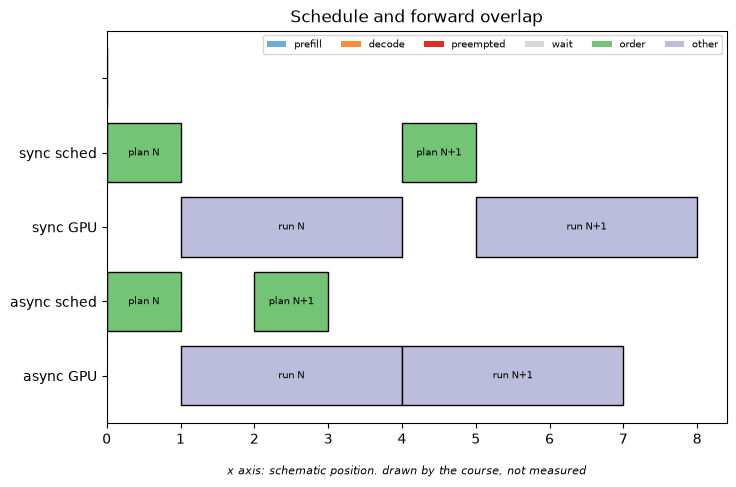

In [23]:
overlap = [
    {"lane": "sync sched", "start": 0, "end": 1, "label": "plan N", "kind": "order"},
    {"lane": "sync GPU", "start": 1, "end": 4, "label": "run N", "kind": "other"},
    {"lane": "sync sched", "start": 4, "end": 5, "label": "plan N+1", "kind": "order"},
    {"lane": "sync GPU", "start": 5, "end": 8, "label": "run N+1", "kind": "other"},
    {"lane": "async sched", "start": 0, "end": 1, "label": "plan N", "kind": "order"},
    {"lane": "async GPU", "start": 1, "end": 4, "label": "run N", "kind": "other"},
    {"lane": "async sched", "start": 2, "end": 3, "label": "plan N+1", "kind": "order"},
    {"lane": "async GPU", "start": 4, "end": 7, "label": "run N+1", "kind": "other"},
]
view.timeline([LEGEND_ROW, *overlap], title="Schedule and forward overlap", x_label="",
              note="x axis: schematic position. drawn by the course, not measured")

정리하면 이 절의 정확한 문장은 "v0.32.0에서 MRV2는 조건이 맞을 때의 기본 경로이고, async scheduling은 끄는 조합이 없을 때 자동으로 켜진다"입니다. 수업 Pod는 `Day07/README.md:75` 기준 이보다 이른 빌드이므로 이 문장이 그 서버에도 맞는지는 이 자료로 말할 수 없습니다(D-08).

**왜 이렇게 설계했나.** MRV2는 PR #25266으로 들어왔고(v0.12.0 실험 기능, 이 자료에서는 부분 확인), 본문은 persistent batch 제거와 GPU에 상주하는 block table을 말합니다. 기본값 전환은 그 PR이 아니라 PR #53183이고 릴리스 노트 기준 v0.29.0입니다(P1-41). 그 PR 본문은 일부 ROCm 모델 예외와 MRV1이 남는 기능이 있다고 씁니다. PDF가 v0.29에 추가됐다고 적은 Triton sampler와 graph memory profiling은 기능은 코드에 있지만 그 시점은 확인되지 않았습니다(D-10(미확인)). async scheduling은 PR #19970이 실험 기능으로 넣었고 본문이 NanoFlow와 비슷한 접근이라고 밝힙니다. 기본으로 켠 것은 PR #27614이고 v0.14.0입니다(P1-42). 동기 대비 얼마나 빨라지는지는 이 자료에 없습니다.

## 7. Python frontend와 수업 서버 (3분)

### 수업 서버와의 차이

여기까지의 정거장 1, 2, 3, 8은 Python API server의 이야기였습니다. v0.32.0에는 대체품이 하나 더 있습니다. 환경변수 `VLLM_USE_RUST_FRONTEND`([vllm/envs.py:170](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/envs.py#L170), 기본 꺼짐)로 켜는 Rust frontend입니다(P1-47).

**공식 문서.** [rust/README.md:3](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/rust/README.md#L3)는 Python API server의 대체품이라고 소개하고, 바로 아래 줄에서 아직 실험 단계이고 기능이 완전하지 않다고 적습니다. 켜면 무엇이 바뀌는지는 계층도 [rust/README.md:17](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/rust/README.md#L17)부터 몇 줄에 나옵니다(P1-48).

수업과 관련된 사실은 세 가지입니다.

- `Day07/README.md:75`는 수업 이미지를 v0.28.1rc1 dev 빌드로 적습니다(R-01). 이 노트북의 기준은 v0.32.0입니다. 둘은 다른 버전입니다.
- 레시피 기본 명령은 `VLLM_USE_RUST_FRONTEND=1`과 `--tokenizer-mode glm5_next`를 씁니다(P1-49, R-14). 수업 README는 이 플래그들을 적지 않습니다. 레시피는 `--disable-flashinfer-autotune`도 쓰는데, v0.32.0의 `vllm/engine/arg_utils.py`에는 이 플래그가 없고 `--enable-flashinfer-autotune`([vllm/engine/arg_utils.py:1802](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/engine/arg_utils.py#L1802))이 있습니다(R-14).
- 그래서 수업 Pod의 frontend는 **모릅니다.** 서버가 보고하는 버전과 시작 로그로 확인해야 합니다.

In [24]:
view.table([
    {"항목": "HTTP 서버", "Python frontend": "FastAPI, Uvicorn", "Rust frontend": "axum (vllm-server crate)"},
    {"항목": "chat template 렌더링", "Python frontend": "API server 프로세스의 renderer", "Rust frontend": "vllm-chat crate"},
    {"항목": "tokenize, 증분 detokenize", "Python frontend": "API server 프로세스", "Rust frontend": "vllm-text crate"},
    {"항목": "reasoning, 도구 파서", "Python frontend": "API server 프로세스", "Rust frontend": "vllm-chat crate"},
    {"항목": "API server 수", "Python frontend": "모드에 따라 1개 이상", "Rust frontend": "1로 고정. 2 이상이면 경고 후 1"},
    {"항목": "EngineCore와의 통신", "Python frontend": "ZMQ", "Rust frontend": "같은 ZMQ 경계"},
    {"항목": "프로세스 시작, 소켓 bind, handshake", "Python frontend": "Python", "Rust frontend": "Python이 그대로 한다"},
    {"항목": "켜는 법", "Python frontend": "기본", "Rust frontend": "VLLM_USE_RUST_FRONTEND=1"},
])

,항목,Python frontend,Rust frontend
0,HTTP 서버,"FastAPI, Uvicorn",axum (vllm-server crate)
1,chat template 렌더링,API server 프로세스의 renderer,vllm-chat crate
2,"tokenize, 증분 detokenize",API server 프로세스,vllm-text crate
3,"reasoning, 도구 파서",API server 프로세스,vllm-chat crate
4,API server 수,모드에 따라 1개 이상,1로 고정. 2 이상이면 경고 후 1
5,EngineCore와의 통신,ZMQ,같은 ZMQ 경계
6,"프로세스 시작, 소켓 bind, handshake",Python,Python이 그대로 한다
7,켜는 법,기본,VLLM_USE_RUST_FRONTEND=1


EngineCore 쪽 정거장(4, 5, 7, 9)과 worker 쪽 정거장(6)은 표에 나오지 않습니다. ZMQ 경계 안쪽은 frontend를 바꿔도 같은 경로라는 뜻입니다(P1-48). 달라지는 곳은 정거장 1, 2, 3, 8입니다. 정거장 3은 ZMQ 경계는 같지만 보내는 쪽이 Rust client입니다([rust/src/engine-core-client/src/client.rs:625](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/rust/src/engine-core-client/src/client.rs#L625)). 그래서 절 4의 `check_admission` 표도 Python 경로의 이야기이고, `--max-num-queued-reqs`와 `--max-num-queued-tokens`는 Rust frontend에 아직 구현되지 않은 인자로 표시돼 있습니다([rust/src/cmd/src/cli/unsupported.rs:366](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/rust/src/cmd/src/cli/unsupported.rs#L366)). 이 Rust 쪽 설명은 코드를 읽은 것이고 실행해 확인하지는 않았습니다. 05와 06에서 다시 이 단서를 붙입니다.

V0 engine은 v0.32.0 소스에 없습니다(P1-46). 옛 패키지 폴더가 없고, 시작할 때 `Initializing a V1 LLM engine` 로그를 남깁니다([vllm/v1/engine/core.py:134](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core.py#L134)).

### 문서와 코드가 다를 때

| 문서가 말하는 것 | 코드가 말하는 것 | 근거 |
|---|---|---|
| GLM-5.3-Flash 레시피의 서버 명령은 `--tokenizer-mode glm5_next`를 쓴다 | v0.32.0의 [vllm/config/model.py:89](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/model.py#L89) 목록에 `glm5_next`가 없다. 필요한 PR #62424는 v0.32.0 커밋(2026-10-17)보다 늦은 2026-10-30에 병합됐다. Python tokenizer 레지스트리에도 없고([vllm/tokenizers/registry.py:79](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/tokenizers/registry.py#L79-L81)), Rust CLI의 렌더러 목록에도 없다([rust/src/cmd/src/cli/tests.rs:943](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/rust/src/cmd/src/cli/tests.rs#L943)). **이 소스 그대로는 레시피 명령이 동작한다고 말할 수 없다.** 코드를 읽은 것이고 서버 명령을 실행해 오류를 확인하지는 않았다 | P1-49, R-14 |

### PDF에서는

이 노트북은 PDF 없이 읽을 수 있습니다. 1장(요청 경로와 상태, Model Runner V2, 시작 로그)을 함께 볼 때 고쳐 읽을 곳은 다음과 같습니다.

| PDF 1장의 표기 | 코드에서 확인한 것 | 근거 |
|---|---|---|
| 예시 명령과 표가 `--enable-prefix-caching`을 "켜는" 플래그처럼 보인다 | [vllm/config/cache.py:141](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/cache.py#L141), 기본이 켜짐이다. 끄는 쪽은 `--no-enable-prefix-caching`이다([vllm/engine/arg_utils.py:380](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/engine/arg_utils.py#L380)) | D-01 |
| 시작 로그의 세 숫자 | 형식과 산수는 절 3의 셀대로다. PDF는 설명용 예시라고 밝혔으니 오류는 아니지만 세 숫자가 서로 맞지 않는다 | D-02 |
| `--gpu-memory-utilization 0.85` | 예시값이다. 기본값은 0.92이다 | D-03 |
| 상태 넷, "PREEMPTED → WAITING 복귀" | 상태는 12개이고 복귀는 큐 위치다. `FINISHED`라는 단일 상태는 없고 `PREEMPTED` 뒤는 모두 종료 상태이며, PDF의 종료 세 경로는 `STOPPED`, `LENGTH_CAPPED`, `ABORTED`에 대응한다. 코드에는 `IGNORED`, `ERROR`, `REPETITION`이 더 있다. 절 5대로 읽는다 | D-06 |
| MRV2의 사용 조건이 없다 | 조건부 기본값이고 문서상 완성 단계가 아니다. 절 6대로 읽는다 | D-08 |
| Triton sampler 등이 v0.29에 추가 | 기능 이름은 코드에 있다. 시점은 소스로 확인할 수 없다(D-10(미확인)) | D-10(미확인) |

**왜 이렇게 설계했나.** 이슈 #40846(RFC)은 `VLLM_USE_RUST_FRONTEND`로 켜는 drop-in 대체품이며 당분간 Python frontend를 대체하지 않는다고 씁니다. 이슈 #44280(로드맵)은 실험적이고 기능이 완전하지 않다고 씁니다. 이슈 안에 벤치마크가 있지만 이 수업의 모델과 구성이 아니므로 성능 수치는 쓰지 않습니다. 레시피 쪽 렌더링을 Rust에 넣은 PR #62424는 v0.32.0보다 늦습니다.

## 직접 해보기

값 하나씩만 바꿉니다. 바꾸기 전에 예측을 적으세요. 처음 실행은 기본값 그대로 돌아갑니다.

### 해보기 1

**먼저 예측하세요.** `max_num_batched_tokens`를 32에서 16으로 바꾸면 `doc`의 첫 token은 몇 번째 step에 나옵니까? `tokens` 칸에서 요청이 처음 둘 이상 섞이는 step은 언제입니까?

In [25]:
BUDGET = 32  # 16으로 바꿔 보세요
exercise = sched_sim.run_sim(sched_sim.doc_faq_chat(), sched_sim.SchedConfig(max_num_batched_tokens=BUDGET))
print("doc 첫 token step:", [e["step"] for e in exercise.events if e["kind"] == "first_token" and e["request_id"] == "doc"])
view.table(exercise.step_rows())

doc 첫 token step: [2]


,step,start_ms,end_ms,tokens,합계,남은 예산,쓰는 block,preempt
0,1,0.0,26.0,doc:32,32,0,2,
1,2,26.0,52.0,doc:22 faq:10,32,0,5,
2,3,52.0,78.0,doc:1 faq:10 chat:21,32,0,8,
3,4,78.0,95.5,doc:1 faq:1 chat:13,15,17,9,
4,5,95.5,107.0,doc:1 faq:1 chat:1,3,29,9,
5,6,107.0,118.5,doc:1 faq:1 chat:1,3,29,9,
6,7,118.5,130.0,doc:1 faq:1 chat:1,3,29,9,
7,8,130.0,141.0,doc:1 faq:1,2,30,6,
8,9,141.0,151.5,doc:1,1,31,4,


### 해보기 2

**먼저 예측하세요.** TP4 구성에 PP를 2로 주면 `world_size`는 몇이 됩니까? 그 값은 절 2 표의 `TP4에 DP 2` 행과 같은 숫자일까요? 같다면 두 구성은 무엇이 다릅니까?

In [26]:
PP = 1  # 2로 바꿔 보세요
print("world_size:", world_size(PP, 4, 1), "(PP =", PP, ", TP = 4, PCP = 1)")
print("EngineCore 수는 DP가 정하므로 이 계산에 없습니다.")

world_size: 4 (PP = 1 , TP = 4, PCP = 1)
EngineCore 수는 DP가 정하므로 이 계산에 없습니다.


### 해보기 3

**먼저 예측하세요.** `override` 항을 256에서 4 또는 8000으로 바꾸면 `정한 항` 칸은 각각 무엇이 됩니까?

In [27]:
OVERRIDE = 256  # 4 또는 8000으로 바꿔 보세요
value, winner = get_max_tokens_like(4096, 54, 9000, override_max_tokens=OVERRIDE)
print("최종 max_tokens:", value, "/ 정한 항:", winner)

최종 max_tokens: 256 / 정한 항: override


## 확인 질문

답은 여기 적지 않습니다. 코드 줄을 근거로 자기 말로 답하세요.

1. 프롬프트 token이 아직 남은 요청과 decode 중인 요청이 한 step에 같이 들어갈 수 있는 이유는 무엇입니까?
2. `max_tokens` 초과와 stop string 종료를 판단하는 프로세스가 왜 다릅니까?
3. 포트가 이미 쓰이고 있을 때 어느 단계에서 실패하고, 왜 그 순서가 유리합니까?
4. KV 크기를 설정값이 아니라 profiling으로 정하면 무엇을 얻고 무엇이 뒤따릅니까?
5. `AsyncLLMEngine` 코드를 찾는 동료에게 어느 파일을 보라고 하겠습니까? 왜 문서와 다릅니까?
6. "MRV2가 기본이다"를 정확하게 다시 말해 보세요.
7. 수업 서버와 이 노트북의 설명이 어긋날 수 있는 지점 두 개를 드세요.

## 블로그 함께 읽기

「Inside vLLM: 서버 시작부터 KV cache까지 소스 코드 톺아보기」, Jongsu Liam Kim, https://blog.liam.kim/posts/2026/10/Inside-vLLM/ (절 제목으로만 참조합니다).

| 블로그 절 | 읽을 때 볼 점 |
|---|---|
| step: LLM request를 쪼개는 단위 | 단계 구분이 없다는 말을 위의 `doc` 표와 대조합니다 |
| vLLM 컴포넌트 | API server와 EngineCore 수가 어떻게 정해지는지 P1-11과 비교합니다 |
| 1. Server mode selection: vllm serve에서 run_server()까지 | 코드에는 `--grpc` 분기가 먼저 있습니다(P1-10) |
| 2. Socket bind: listen 전의 port 선점 | listen은 경로마다 위치가 다릅니다. 단일 server는 Uvicorn 안, `peer_loads` 경로는 vLLM이 직접 부릅니다(P1-12) |
| 3. Engine config: CLI 인자에서 VllmConfig까지 | 03에서 다시 봅니다 |
| 5. EngineCore startup: model load, KV cache allocation, scheduler setup | 절 3의 초기화 순서 표와 대조합니다 |
| 계층별 request 객체 | 코드의 chat 경로는 `OnlineRenderer`에 위임합니다(P1-27) |
| 생성 한도를 정하는 값들 | 함수 경계를 코드와 대조합니다. `get_max_tokens`는 `fallback` 결정과 최솟값 계산을 하고, 요청 값 선택은 호출부, `override`는 생성자입니다(P1-32) |
| 설계 결정: 처음부터 다시 만든 Model Runner V2 | 기본값 전환 PR은 #53183입니다(P1-41) |
| 설계 결정: API server에서 하는 detokenize와 stop string 검사 | 이슈 #6797과 PR #9826을 같이 봅니다 |

## 정리

- 실행의 단위는 step이고, scheduler는 계산 수가 전체 수를 따라잡도록 token을 나눠 줍니다. prefill과 decode는 scheduler에 없는 말입니다.
- 프로세스는 API server, EngineCore, GPU worker입니다. 글자로 바꾸는 일은 API server, block을 나누는 일은 EngineCore, forward는 worker가 맡습니다.
- 시작 순서는 소켓 bind, 설정, client, EngineCore(executor, KV, scheduler), READY, HTTP입니다. KV 크기는 기본 설정에서 시작할 때 모델을 돌려 본 결과로 정해집니다.
- 객체 사슬은 `ChatCompletionRequest`, `EngineInput`, `EngineCoreRequest`, `Request`, `SchedulerOutput`, `ModelRunnerOutput`, `EngineCoreOutputs`, `RequestOutput`입니다.
- 상태는 12개이고 종료 판정은 값 비교입니다. preempt는 상태가 `PREEMPTED`이고 위치가 waiting 맨 앞입니다.
- MRV2와 async scheduling은 조건부입니다. 수업 서버는 다른 버전이고 frontend도 모릅니다.

이 노트북이 넘기는 것: "schedule 안에서 block을 받는다"는 빈칸을 02a가 채웁니다.

## 참고한 근거

ID의 내용은 `docs/sources/part1.md`, `docs/sources/pdf-diff.md`에 있습니다. P2-03은 `part2.md`, P3-14는 `part3.md`에 있습니다.

- step: P1-01, P1-02, P2-03
- 프로세스 경계: P1-03, P1-04, P1-05, P1-07, P1-08, P1-09, P1-11, P1-17, R-02, R-07
- 서버 초기화: P1-06, P1-10, P1-12, P1-13, P1-14, P1-15, P1-16, P1-18, P1-19, P1-20, P1-21, P1-22, P1-23, P1-24, P1-25, P1-26, P1-51, D-02, D-03, R-06
- request 경로: P1-27, P1-28, P1-29, P1-30, P1-31, P1-32, P1-33, P1-34, P1-35, P1-44, P1-45, P3-14
- 상태: P1-36, P1-37, P1-38, D-06
- MRV2와 async: P1-39, P1-40, P1-41, P1-42, P1-43, D-08, D-09, D-10(미확인)
- frontend: P1-46, P1-47, P1-48, P1-49, R-01, R-14
- 실제 클래스 실행: `data/reference_sched.json`(`docs/reference/sched.md`)
- PDF 대조: D-01, D-02, D-03, D-06, D-08, D-10(미확인)

미확인 표시는 근거 대장(`docs/sources/`)의 상태가 미확인이라는 뜻입니다. 해당 문장은 사실로 쓰지 않았습니다. 강사 메모의 15~20분은 `2026-09-15 강사 메모, v0.28 dev` 값입니다. 시뮬레이터 결과는 측정이 아닙니다. 스케줄러 표는 실제 `Scheduler` 클래스를 CPU에서 돌린 기록과 맞춘 것이고(`data/reference_sched.json`), 서버를 띄운 관찰이 아닙니다.